In [1]:
from SALib.sample import sobol
from SALib.analyze import sobol
from SALib.sample import latin
from SALib.analyze import pawn
import matplotlib.pyplot as plt
import matplotlib
import numpy as np
import re
import pandas as pd
from scipy.interpolate import RBFInterpolator
from SALib.sample import saltelli
from scipy import optimize
from dolfin import *
import matplotlib as mpl
from scipy.optimize import curve_fit
from matplotlib.pyplot import cm
from scipy.spatial import ConvexHull, convex_hull_plot_2d
import shapely
from shapely import Polygon, Point
from matplotlib.collections import LineCollection
import re
from scipy import stats
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.interpolate import CubicSpline
from numpy import linalg
from numpy import inf
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from scipy.optimize import differential_evolution
import dill
import seaborn as sns
import plotly.express as px

In [9]:
def sigmoid_r(r, K, L, r0):
    return K / (1 + np.exp(-L * (r0 - r)))

def sigmoid_t(t, K, L, tn):
    return K / (1 + np.exp(L * (tn - t)))

def initial_pulse(r, A, s, r0):
    return A * np.exp(-s * np.abs(r - r0) ** 2)

def tolerant_mean(arrs):
    lens = [len(i) for i in arrs]
    arr = np.ma.empty((np.max(lens),len(arrs)))
    arr.mask = True
    for idx, l in enumerate(arrs):
        arr[:len(l),idx] = l
    return arr.mean(axis = -1), arr.std(axis=-1)

def round_to_multiple(number, multiple):
    return multiple * np.round(number / multiple)

def round_to_signif(x, p):
    x = np.asarray(x)
    x_positive = np.where(np.isfinite(x) & (x != 0), np.abs(x), 10**(p-1))
    mags = 10 ** (p - 1 - np.floor(np.log10(x_positive)))

def get_n(s):
    match = re.search(r'\d+$', s)
    if match:
        return int(match.group())
    else:
        return None

def PDE(pars, upar, time, plot):
    '''
    pars = dictionary of parameters to fit (key = parameter name, value = parameter value).
    upar = parameters of initial condition [A, s, r0].
    time = hours.
    plot = whether or not to show plot of PDE solution (1=yes).
    '''
    alphval = pars[0]
    beta = Constant(pars[1])
    v_sval = pars[2]
    s_scal =  Constant(pars[3])
    D = Constant(pars[4])

    # Define the problem
    Length = 3 # 40.0
    left = 1e-3
    dX = 0.01
    X = np.arange(left, Length, dX)
    nx = len(X)
    nT = int(time * 10) # 900
    keep = 10 # get every hour
    mesh = IntervalMesh(nx, left, Length)
    P1 = FiniteElement('P', interval, 1)
    element = MixedElement([P1, P1])
    V = FunctionSpace(mesh, element)
    cmap2 = mpl.colormaps["spring"]
    cmap = mpl.colormaps["winter"]
    set_log_level(LogLevel.WARNING)

    density_tip_t = np.zeros((int(nT / keep), nx))
    density_in_t = np.zeros((int(nT / keep), nx))
    n_sat_r = []
    rho_sat_r = []
    x_r = []

    # Define the parameters
    T = time # 90
    dt = T/nT
    # alphval = 0.039
    cval = 0.6
    # Define the initial condition
    u0_str = str(upar[0]) + '*exp(-0.5*' + str(upar[1]) + '*pow(abs(x[0]-' + str(upar[2]) + '),2))'
    u0 = Expression((u0_str, '0.0'), degree=1)
    #define radial coordinate
    rexp = Expression(('1.0/x[0]', '0.0'), degree=1)
    r = interpolate(rexp, V)
    invr, _ = split(r)
    # Define other elements

    u_n = interpolate(u0, V)
    u = Function (V)
    n, rho = split(u)
    n_n, rho_n= split(u_n)
    v_1, v_2 = TestFunctions(V)
    k = Constant((1,))

    # s_scal =  Constant(0.0288) # Constant(0.2)
    # beta = Constant(0.022)
    alpha = Constant(alphval)
    # D = Constant(0.02)

    n_mid = 0.5*(n_n + n)
    # v_sval = 0.235
    v_s = Constant((v_sval,))

    F = n * v_1 * dx - n_n * v_1 * dx
    # Diffusion term
    F += D * dot(grad(n), grad(v_1)) * dt * dx
    # Cylindrical correction terms using invr
    F += invr * D * dot(grad(n), Constant((1.0,))) * v_1 * dt * dx
    F += dt * dot(grad(n_mid), v_s) * v_1 * dx
    F += invr * dt * n_mid * Constant(v_sval) * v_1 * dx

    F -= dt * s_scal * n * v_2 * dx - (rho - rho_n) * v_2 * dx
    F += beta * v_1 * rho * n * dt * dx
    F -= alpha * n * v_1 * dt * dx

    # Apply the boundary conditions (left=left, right=Length)
    u_L = (Constant(0.0), Constant(0.0))
    u_R = (Constant(0.0), Constant(0.0))
    bc_L = DirichletBC(V, u_L, f'near(x[0], {left})')
    bc_R = DirichletBC(V, u_R, f'near(x[0], {Length})')
    bcs = [bc_L, bc_R]

    t = 0.0
    a, L = lhs(F), rhs(F)
    V2 = FunctionSpace(mesh, 'P', 1)
    # X = np.arange(left, Length, dx)
    poss = []

    i=0

    if plot == 1:
        fig, axs = plt.subplots(3, 1)
    for t in np.linspace(0,T,nT):
        try:
            solve(F==0, u,bcs)
            u_n.assign(u)
            _n, _rho= u.split()

            if i%keep==0:# i%100==0:
                n_field = interpolate(_n, V2)
                rho_field = interpolate(_rho, V2)
                density_tip_t[int(i / keep), :] = [n_field(x) for x in X]
                density_in_t[int(i / keep), :] = [rho_field(x) for x in X]
                poss.append(np.argmax([n_field(x) for x in X]))
                if plot == 1:
                    axs[0].plot(X, [n_field(x) for x in X], color=cmap2(t / T))
                    axs[1].plot(X, [rho_field(x) for x in X], color=cmap(t / T))

                    if i > nT / 2:
                        axs[2].plot(X, [n_field(x) for x in X], color=cmap2(t / T))

            xi = np.argmax([n_field(x) for x in X]) * (Length / nx) - upar[2]
            if round(xi, 2) % 0.05 <= 0.02:
                if round_to_multiple(xi, 0.05) not in x_r:
                    rho_nonzero = density_in_t[int(i / keep), :][density_in_t[int(i / keep), :] > 0.1]
                    n_sat_r.append(max([n_field(x) for x in X]))
                    if len(rho_nonzero) > 0:
                        rho_sat_r.append(np.median(rho_nonzero))
                    else:
                        rho_sat_r.append(0)
                    x_r.append(round_to_multiple(xi, 0.05))

        except RuntimeError as e:
            print('hour ' + str(t))
            print(e)
            if i%keep==0:# i%100==0:
                density_tip_t[int(i / keep), :] = np.zeros(len(X))
                density_in_t[int(i / keep), :] = np.zeros(len(X))
                poss.append(0)
        i += 1

    plt.show()

    dxdt = np.array(poss)*Length/nx - upar[2]

    n_sat_t = []
    rho_sat_t = []

    for t in np.arange(T):
        # collect PDE output for each hour
        # saturation density
        n_sat_t.append(np.max(density_tip_t[t, :]))
        rho_nonzero = density_in_t[t, :][density_in_t[t, :] > 0.1]
        if len(rho_nonzero) > 0:
            rho_sat_t.append(np.median(rho_nonzero))
        else:
            rho_sat_t.append(0)
    
    x_r = np.array(list(x_r))

    data_t = pd.DataFrame({'n': np.array(n_sat_t), 'rho': np.array(rho_sat_t), 'c': dxdt, 't': np.arange(T)})
    data_r = pd.DataFrame({'n': np.array(n_sat_r), 'rho': np.array(rho_sat_r), 'r': x_r})

    for r in np.arange(data_r['r'].max() + 0.05, 1.05, 0.05):
        data_r.loc[len(data_r)] = [0, 0, round_to_multiple(r, 0.05)]

    return data_t, data_r

def evaluate_PDE_rho(best, upper, lower, upar, time):
    y_t_best, y_r_best = PDE(best, upar, time, 0)
    y_t_best = y_t_best.rename(columns={'n': 'n_best', 'rho': 'rho_best', 'c': 'r_best'})
    y_t_upper, y_r_upper = PDE(upper, upar, time, 0)
    y_t_upper = y_t_upper.rename(columns={'n': 'n_upper', 'rho': 'rho_upper', 'c': 'r_upper'})
    y_t_lower, y_r_lower = PDE(lower, upar, time, 0)
    y_t_lower = y_t_lower.rename(columns={'n': 'n_lower', 'rho': 'rho_lower', 'c': 'r_lower'})
    y_t = y_t_best.merge(y_t_lower, on = 't', how = 'inner')
    y_t = y_t.merge(y_t_upper, on = 't', how = 'inner')
    # y_t['n_mean'] = y_t[['n_best', 'n_lower', 'n_upper']].mean(axis=1)
    y_t['rho_mean'] = y_t[['rho_best', 'rho_lower', 'rho_upper']].mean(axis=1)
    return y_t['rho_mean'].mean()

def evaluate_PDE_c(best, upper, lower, upar, time):
    y_t_best, y_r_best = PDE(best, upar, time, 0)
    y_t_best = y_t_best.rename(columns={'n': 'n_best', 'rho': 'rho_best', 'c': 'r_best'})
    y_t_upper, y_r_upper = PDE(upper, upar, time, 0)
    y_t_upper = y_t_upper.rename(columns={'n': 'n_upper', 'rho': 'rho_upper', 'c': 'r_upper'})
    y_t_lower, y_r_lower = PDE(lower, upar, time, 0)
    y_t_lower = y_t_lower.rename(columns={'n': 'n_lower', 'rho': 'rho_lower', 'c': 'r_lower'})
    y_t = y_t_best.merge(y_t_lower, on = 't', how = 'inner')
    y_t = y_t.merge(y_t_upper, on = 't', how = 'inner')
    y_t['n_mean'] = y_t[['n_best', 'n_lower', 'n_upper']].mean(axis=1)
    y_t['rho_mean'] = y_t[['rho_best', 'rho_lower', 'rho_upper']].mean(axis=1)
    y_t['r_mean'] = y_t[['r_best', 'r_lower', 'r_upper']].mean(axis=1)
    res = stats.linregress(y_t['t'], y_t['r_mean'])

    return res.slope

### Collected Data

In [13]:
params = ['max_l', 'split_l', 'max_r', 's_p', 'f_p', 'f_separation', 'W_A']
param_names = ['chem_species.max_seg_length', 'chem_species.seg_split_length',
               'chem_species.max_seg_radius', 'chem_species.splitting_probability',
               'chem_species.fusion_probability', 'chem_species.max_fusion_separation',
               'cell_force.fungi_boundary_width'] 

In [4]:
headers = ['sim_name', 'alpha', 'beta', 'vd', 'sg', 'D']
PDE_names = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean.csv', header=None, names=headers)['sim_name']

# PDE_mn_good = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean_good.csv', header=None, names=headers)
# PDE_mn_good['error'] = 0
# PDE_mn_nofuse = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean_nofuse.csv', header=None, names=headers)
# PDE_mn_nofuse['error'] = 1
# PDE_mn_timeout = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean_timeout.csv', header=None, names=headers)
# PDE_mn_timeout['error'] = 2
# PDE_mn_df = pd.concat([PDE_mn_good, PDE_mn_nofuse, PDE_mn_timeout], ignore_index=True)
PDE_mn_df = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean.csv', header=None, names=headers)
PDE_mn = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean.csv', header=None, names=headers)[['alpha', 'beta', 'vd', 'sg', 'D']].to_numpy()
mn_scaler = MinMaxScaler()
mn_scaler.fit(PDE_mn)
PDE_mn_norm = mn_scaler.transform(PDE_mn)

# PDE_lb_good = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_lb_good.csv', header=None, names=headers)
# PDE_lb_good['error'] = 0
# PDE_lb_nofuse = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_lb_nofuse.csv', header=None, names=headers)
# PDE_lb_nofuse['error'] = 1
# PDE_lb_timeout = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_lb_timeout.csv', header=None, names=headers)
# PDE_lb_timeout['error'] = 2
# PDE_lb_df = pd.concat([PDE_lb_good, PDE_lb_nofuse, PDE_lb_timeout], ignore_index=True)
PDE_lb_df = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_lb.csv', header=None, names=headers)
PDE_lb = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_lb.csv', header=None, names=headers)[['alpha', 'beta', 'vd', 'sg', 'D']].to_numpy()
lb_scaler = MinMaxScaler()
lb_scaler.fit(PDE_lb)
PDE_lb_norm = lb_scaler.transform(PDE_lb)

# PDE_ub_good = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_ub_good.csv', header=None, names=headers)
# PDE_ub_good['error'] = 0
# PDE_ub_nofuse = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_ub_nofuse.csv', header=None, names=headers)
# PDE_ub_nofuse['error'] = 1
# PDE_ub_timeout = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_ub_timeout.csv', header=None, names=headers)
# PDE_ub_timeout['error'] = 2
# PDE_ub_df = pd.concat([PDE_ub_good, PDE_ub_nofuse, PDE_ub_timeout], ignore_index=True)
PDE_ub_df = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_ub.csv', header=None, names=headers)
PDE_ub = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_ub.csv', header=None, names=headers)[['alpha', 'beta', 'vd', 'sg', 'D']].to_numpy()
ub_scaler = MinMaxScaler()
ub_scaler.fit(PDE_ub)
PDE_ub_norm = ub_scaler.transform(PDE_ub)

In [5]:
# PDE_ub = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_ub.csv', header=None, names=headers)[['sim_name', 'alpha', 'beta', 'vd', 'sg', 'D']]
# sim_names = PDE_names.to_list()
# PDE_ub_sorted = pd.DataFrame(columns=['n','sim_name', 'alpha', 'beta', 'vd', 'sg', 'D'])
# for sim in sim_names:
#     n = get_n(sim)
#     sim_row = PDE_ub.loc[PDE_ub['sim_name'] == sim]
#     sim_row.insert(0, 'n', n)
#     PDE_ub_sorted = pd.concat([PDE_ub_sorted, sim_row], ignore_index=True)

In [6]:
# from natsort import natsort_keygen
# PDE_ub_sorted = PDE_ub_sorted.sort_values(by=['n'], key=natsort_keygen())
# PDE_ub_sorted.to_csv('pareto_ub_sorted.csv', index = False)

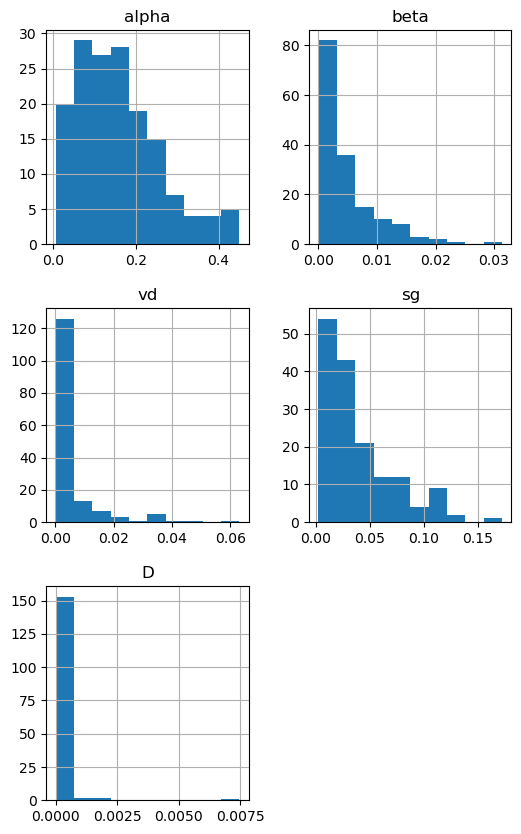

In [7]:
hist = PDE_lb_df[['alpha', 'beta', 'vd', 'sg', 'D']].hist(bins=10, figsize = (6, 10))
# plt.savefig('PDE_dist.png')

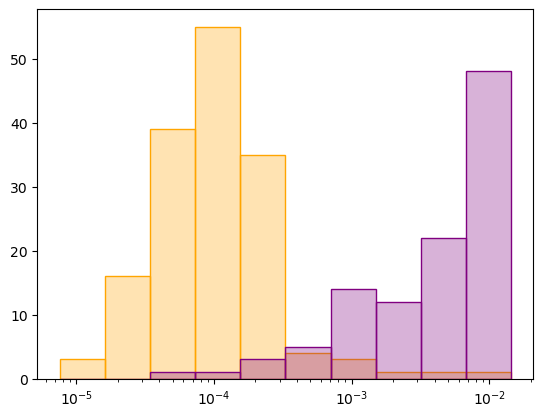

In [8]:
fig, ax = plt.subplots()
bns = 10
logbins = np.geomspace(min(PDE_mn_df['D']), max(PDE_mn_df['D']), bns+1)
ax.hist(PDE_mn_df['D'], bins=logbins, alpha = 0.3, facecolor = 'orange')
ax.hist(PDE_mn_df['D'], bins=logbins, alpha = 1, facecolor = 'None', edgecolor = 'orange')
ax.hist(PDE_mn_df['beta'], bins=logbins, alpha = 0.3, facecolor = 'purple')
ax.hist(PDE_mn_df['beta'], bins=logbins, alpha = 1, facecolor = 'None', edgecolor = 'purple')
ax.set_xscale('log')

In [9]:
PDE_mn_df['rho_sat'] = 2 * PDE_mn_df['alpha'] / PDE_mn_df['beta']
PDE_mn_df['c'] = PDE_mn_df['vd'] + 2 * np.sqrt(PDE_mn_df['D'] * PDE_mn_df['alpha'])

In [10]:
PDE_mn_df

,sim_name,alpha,beta,vd,sg,D,rho_sat,c
0,output_fungi_104,0.193876,0.006643,0.011279,0.059516,0.000182,58.367777,0.023155
1,output_fungi_131,0.178985,0.000938,0.005930,0.083790,0.000077,381.621753,0.013363
2,output_fungi_105,0.239194,0.013272,0.015058,0.073960,0.000166,36.044930,0.027676
3,output_fungi_132,0.360452,0.052221,0.024576,0.096120,0.000051,13.804747,0.033141
4,output_fungi_133,0.410329,0.042846,0.029366,0.102816,0.000052,19.153860,0.038645
...,...,...,...,...,...,...,...,...
153,output_fungi_41,0.373206,0.023138,0.016663,0.084590,0.000129,32.258900,0.030562
154,output_fungi_74,0.364894,0.008086,0.002487,0.107249,0.000303,90.249509,0.023531
155,output_fungi_182,0.233616,0.002312,0.012666,0.098582,0.000307,202.094716,0.029596
156,output_fungi_249,0.474658,0.018382,0.013776,0.095503,0.000194,51.644711,0.032948


In [31]:
import pandas as pd
import numpy as np
import re
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from scipy import stats


In [16]:
ABM_256_inputs = pd.read_csv('../256_inputs/256_inputs.csv')
headers = ['sim_name', 'alpha', 'beta', 'vd', 'sg', 'D']
PDE_names = pd.read_csv('../pareto_mean.csv', header=None, names=headers)['sim_name']

ABM_sample = np.zeros((len(PDE_names), 7))
j = 0
sim_names = PDE_names.to_list()
for sim in sim_names:
    n = get_n(sim)
    sim_row = ABM_256_inputs.iloc[n]
    i = 0
    for name in param_names:
        ABM_sample[j, i] = sim_row[name]
        i += 1
    j += 1

# [[17.5e-4, 52.5e-4], [2.5e-4, 7.5e-4], [1.25e-4, 3.75e-4], [0.1, 0.3], [0.005, 0.015], [3.0e-4, 9.0e-4], [0.5e-4, 1.5e-4]]
ABM_scaler = MinMaxScaler()
# ABM_toscale = np.append(ABM_sample, [[16.5e-4, 16.5e-4 - 8.5e-4, 0.25e-4, 0.05, 0.004, 2.0e-4, 0.4e-4]], axis=0) # adding smallest and largest possible values
# ABM_toscale = np.append(ABM_toscale, [[53.5e-4, 53.5e-4 - 1.5e-4, 4.75e-4, 0.4, 0.025, 10.0e-4, 1.5e-4]], axis=0)
ABM_toscale = np.append(ABM_sample, [[17.5e-4, 17.5e-4 - 7.5e-4, 1.25e-4, 0.1, 0.005, 3.0e-4, 0.5e-4]], axis=0) # adding smallest and largest possible values
ABM_toscale = np.append(ABM_toscale, [[52.5e-4, 52.5e-4 - 2.5e-4, 3.75e-4, 0.3, 0.015, 9.0e-4, 1.5e-4]], axis=0)
ABM_scaler.fit(ABM_toscale)
ABM_norm = ABM_scaler.transform(ABM_sample)

In [17]:
ABM_df = pd.DataFrame(ABM_sample, columns=params)
ABM_df.insert(0, 'sim_name', sim_names)

In [19]:
PDE_mn_df = pd.read_csv('../pareto_mean.csv', header=None, names=headers)

in_out = ABM_df.merge(PDE_mn_df, on = 'sim_name', how ='inner')
in_out['resistance'] = in_out['max_l'] / (in_out['max_r'] ** 2)

In [23]:
in_out

,sim_name,max_l,split_l,max_r,s_p,f_p,f_separation,W_A,alpha,beta,vd,sg,D,resistance
0,output_fungi_104,0.004208,0.003929,0.000332,0.20,0.01388,0.000831,0.000142,0.193876,0.006643,0.011279,0.059516,0.000182,38176.803600
1,output_fungi_131,0.003251,0.002546,0.000341,0.19,0.00677,0.000514,0.000101,0.178985,0.000938,0.005930,0.083790,0.000077,27958.135895
2,output_fungi_105,0.004048,0.003493,0.000179,0.11,0.00523,0.000778,0.000062,0.239194,0.013272,0.015058,0.073960,0.000166,126338.129272
3,output_fungi_132,0.005245,0.004936,0.000159,0.25,0.01391,0.000871,0.000059,0.360452,0.052221,0.024576,0.096120,0.000051,207468.059017
4,output_fungi_133,0.004657,0.003994,0.000239,0.22,0.01369,0.000634,0.000122,0.410329,0.042846,0.029366,0.102816,0.000052,81528.684722
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153,output_fungi_41,0.004112,0.003406,0.000289,0.24,0.01453,0.000679,0.000121,0.373206,0.023138,0.016663,0.084590,0.000129,49233.126998
154,output_fungi_74,0.002452,0.002125,0.000136,0.10,0.01438,0.000736,0.000093,0.364894,0.008086,0.002487,0.107249,0.000303,132569.204152
155,output_fungi_182,0.003004,0.002745,0.000138,0.19,0.00965,0.000418,0.000086,0.233616,0.002312,0.012666,0.098582,0.000307,157739.970594
156,output_fungi_249,0.004365,0.003782,0.000140,0.27,0.01478,0.000661,0.000098,0.474658,0.018382,0.013776,0.095503,0.000194,222704.081633


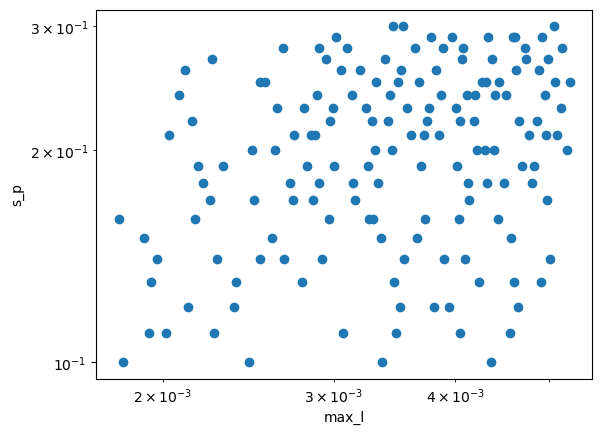

In [26]:
plot1 = 'max_l'
plot2 = 's_p'
fig, ax = plt.subplots()
sc = ax.scatter(in_out[plot1], in_out[plot2])
ax.set_xlabel(plot1)
ax.set_ylabel(plot2)
ax.set_xscale('log')
ax.set_yscale('log')

<>:58: SyntaxWarning: invalid escape sequence '\e'
<>:73: SyntaxWarning: invalid escape sequence '\e'
<>:58: SyntaxWarning: invalid escape sequence '\e'
<>:73: SyntaxWarning: invalid escape sequence '\e'
/var/folders/nv/8htcvdk16flcwrc093r8v2v00000gp/T/ipykernel_43571/783930617.py:58: SyntaxWarning: invalid escape sequence '\e'
  cbar.ax.set_ylabel("Elasticity ($\epsilon$)", rotation=-90, va="bottom", fontsize=12)
/var/folders/nv/8htcvdk16flcwrc093r8v2v00000gp/T/ipykernel_43571/783930617.py:73: SyntaxWarning: invalid escape sequence '\e'
  ax.set_title("Global Parameter Elasticity Matrix ($\epsilon_{Y,X}$)\n"



=== Calculated Global Elasticities ===
Values represent the % change in Output per 1% change in Input:
              alpha   beta     vd     sg      D    rho      c
max_l        -0.534  1.925 -0.046 -0.572  0.580 -2.459  0.020
split_l      -0.496  1.564 -0.106 -0.541  0.495 -2.061 -0.030
max_r        -0.105 -1.462 -0.428 -0.135 -0.606  1.357 -0.413
s_p           0.374  0.257  0.593 -0.088  0.524  0.117  0.563
f_p          -0.010  0.135 -0.063  0.097 -0.481 -0.144 -0.171
f_separation  0.173  3.008  0.424 -0.169 -0.199 -2.835  0.069
W_A          -0.097 -0.426  0.015  0.119  0.362  0.328  0.049
resistance   -0.048  0.835  0.147 -0.043  0.311 -0.883  0.152


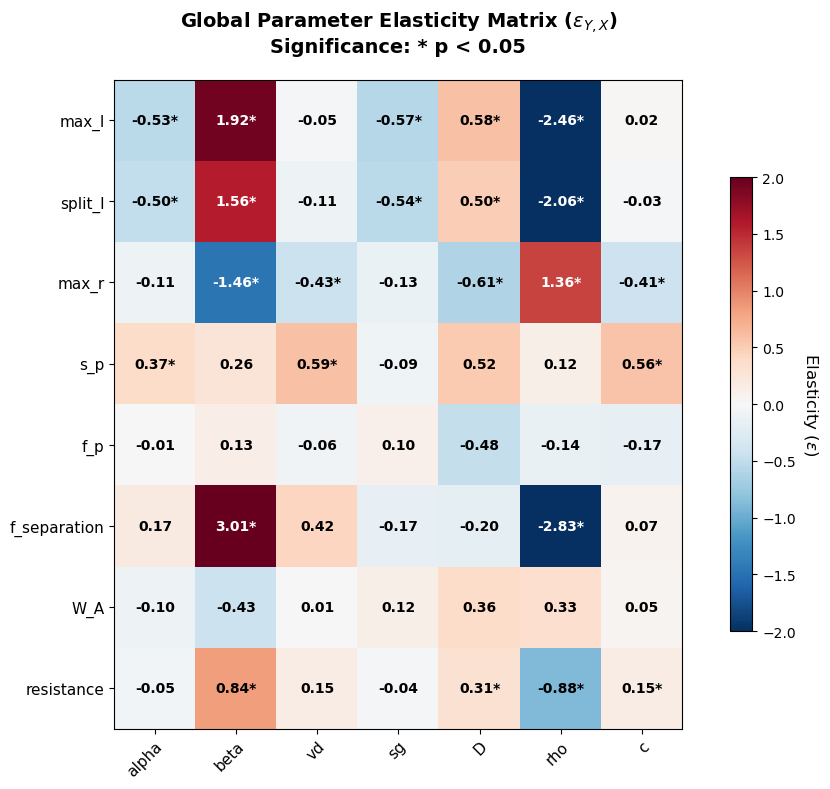

In [33]:
# =====================================================================
# APPEND THIS TO THE END OF YOUR SCRIPT
# =====================================================================

# 1. Calculate the derived BARE outputs
in_out['rho'] = 2.0 * in_out['alpha'] / in_out['beta']
in_out['c'] = in_out['vd'] + 2.0 * np.sqrt(in_out['D'] * in_out['alpha'])

# 2. Define our input and output variables for the elasticity analysis
elasticity_inputs = ['max_l', 'split_l', 'max_r', 's_p', 'f_p', 'f_separation', 'W_A', 'resistance']
elasticity_outputs = ['alpha', 'beta', 'vd', 'sg', 'D', 'rho', 'c']

# 3. Compute the global elasticities using log-log linear regressions
elasticity_df = pd.DataFrame(index=elasticity_inputs, columns=elasticity_outputs)
p_values_df = pd.DataFrame(index=elasticity_inputs, columns=elasticity_outputs)

for out_var in elasticity_outputs:
    for in_var in elasticity_inputs:
        # Filter out NaN, zero, or negative values to allow log transformation
        clean_df = in_out[[in_var, out_var]].dropna()
        clean_df = clean_df[(clean_df[in_var] > 0) & (clean_df[out_var] > 0)]
        
        if len(clean_df) > 10:
            log_x = np.log(clean_df[in_var])
            log_y = np.log(clean_df[out_var])
            
            # The slope of a log-log regression represents the elasticity
            slope, intercept, r_value, p_value, std_err = stats.linregress(log_x, log_y)
            elasticity_df.loc[in_var, out_var] = slope
            p_values_df.loc[in_var, out_var] = p_value
        else:
            elasticity_df.loc[in_var, out_var] = np.nan

# Convert elements to float
elasticity_df = elasticity_df.astype(float)
p_values_df = p_values_df.astype(float)

# Print the elasticity table to console
print("\n=== Calculated Global Elasticities ===")
print("Values represent the % change in Output per 1% change in Input:")
print(elasticity_df.round(3))

# 4. Plot the Elasticity Matrix as a Heatmap
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(elasticity_df.values, cmap='RdBu_r', vmin=-2, vmax=2)

# Set up ticks and labels
ax.set_xticks(np.arange(len(elasticity_outputs)))
ax.set_yticks(np.arange(len(elasticity_inputs)))
ax.set_xticklabels(elasticity_outputs, fontsize=11)
ax.set_yticklabels(elasticity_inputs, fontsize=11)

# Rotate output labels for readability
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

# Add colorbar
cbar = ax.figure.colorbar(im, ax=ax, shrink=0.7)
cbar.ax.set_ylabel("Elasticity ($\epsilon$)", rotation=-90, va="bottom", fontsize=12)

# Annotate each cell with its value, marking statistical significance
for i in range(len(elasticity_inputs)):
    for j in range(len(elasticity_outputs)):
        val = elasticity_df.values[i, j]
        p_val = p_values_df.values[i, j]
        
        # Determine annotation text (add asterisk if statistically significant)
        sig_marker = "*" if p_val < 0.05 else ""
        text_color = "white" if abs(val) > 1.0 else "black"
        
        ax.text(j, i, f"{val:.2f}{sig_marker}",
                ha="center", va="center", color=text_color, fontsize=10, weight="bold")

ax.set_title("Global Parameter Elasticity Matrix ($\epsilon_{Y,X}$)\n"
             "Significance: * p < 0.05", fontsize=14, weight="bold", pad=20)
plt.tight_layout()
plt.savefig("global_elasticity_matrix.png", dpi=300)
plt.show()


  RENEWAL THEORY (BRANCHING CLOCK) TEST RESULTS  
Predictor 1 (Growth Window: p_s * s_g / l_split):
  - R² correlation: 0.3203
  - Fitted Slope:   0.0169
  - Intercept:      0.1973 (Theoretical Target: 0.0)
--------------------------------------------------
Predictor 2 (Average Length: p_s * s_g / l_avg):
  - R² correlation: 0.2879
  - Fitted Slope:   0.0122
  - Intercept:      0.1926
  TARGET ELASTICITIES VS. EMPIRICAL MEASUREMENTS  
Elasticity of branching to splitting probability (ε_α,ps):
  - Measured:       0.3744
  - Theoretical:    +1.0000 (Unitary scale-free response)
--------------------------------------------------
Elasticity of branching to growth window (ε_α,l_split):
  - Measured:       -0.4962
  - Theoretical:    -1.0000 (Inverse frequency scaling)
--------------------------------------------------
Elasticity of branching to average length (ε_α,l_avg):
  - Measured:       -0.5315


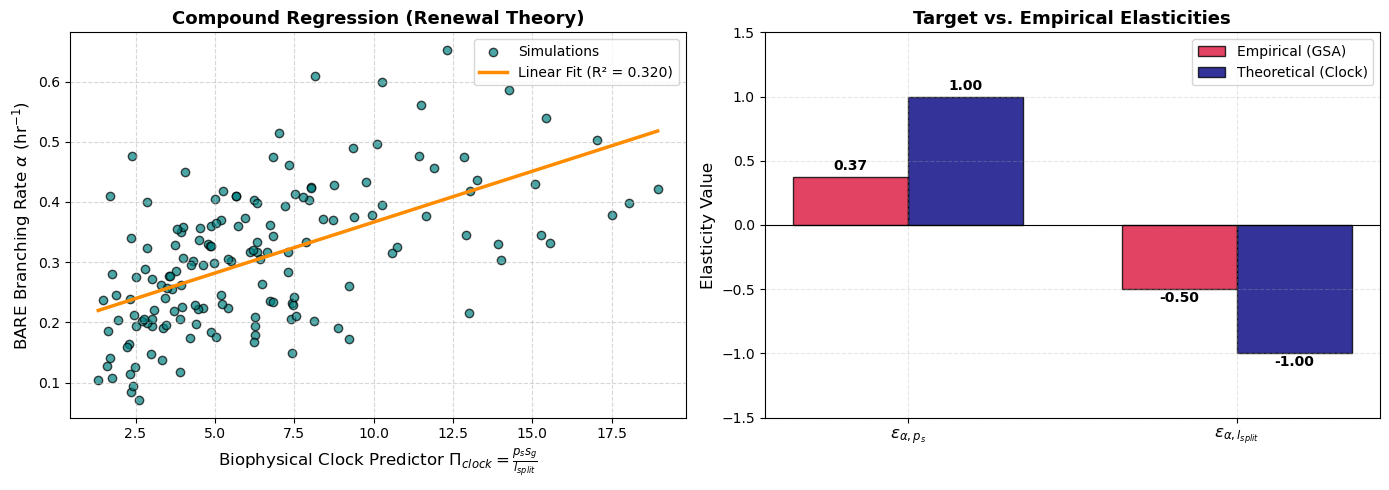

In [34]:
# =====================================================================
# RENEWAL THEORY (BRANCHING CLOCK) VALIDATION SUITE

# 1. Define the biophysical components from the dataframe
# split_l in your dataframe represents the growth window (l_max - l_birth)
growth_window = in_out['split_l'] 
p_s = in_out['s_p']
s_g = in_out['sg']
alpha = in_out['alpha']

# Calculate the average tip length during its life cycle: l_avg = l_max - 0.5 * l_split
l_avg = in_out['max_l'] - 0.5 * in_out['split_l']

# 2. Compute the Compound Biophysical Predictors
# Predictor A: Based purely on the division cycle time (growth window)
in_out['Pi_clock_window'] = (p_s * s_g) / growth_window

# Predictor B: Based on the average tip length (biomass/metabolic scaling)
in_out['Pi_clock_avg'] = (p_s * s_g) / l_avg

# 3. Perform Linear Regressions (Alpha vs. Predictors)
slope_win, inter_win, r_win, p_win, se_win = stats.linregress(in_out['Pi_clock_window'], alpha)
slope_avg, inter_avg, r_avg, p_avg, se_avg = stats.linregress(in_out['Pi_clock_avg'], alpha)

# 4. Calculate Empirical Log-Log Elasticities
# Elasticity of alpha with respect to splitting probability (p_s)
slope_eps_ps, _, _, _, _ = stats.linregress(np.log(p_s), np.log(alpha))

# Elasticity of alpha with respect to the growth window (l_split)
slope_eps_win, _, _, _, _ = stats.linregress(np.log(growth_window), np.log(alpha))

# Elasticity of alpha with respect to the average length (l_avg)
slope_eps_lavg, _, _, _, _ = stats.linregress(np.log(l_avg), np.log(alpha))


# 5. Display the Quantitative Results
print("\n" + "="*50)
print("  RENEWAL THEORY (BRANCHING CLOCK) TEST RESULTS  ")
print("="*50)
print(f"Predictor 1 (Growth Window: p_s * s_g / l_split):")
print(f"  - R² correlation: {r_win**2:.4f}")
print(f"  - Fitted Slope:   {slope_win:.4f}")
print(f"  - Intercept:      {inter_win:.4f} (Theoretical Target: 0.0)")
print("-" * 50)
print(f"Predictor 2 (Average Length: p_s * s_g / l_avg):")
print(f"  - R² correlation: {r_avg**2:.4f}")
print(f"  - Fitted Slope:   {slope_avg:.4f}")
print(f"  - Intercept:      {inter_avg:.4f}")
print("="*50)
print("  TARGET ELASTICITIES VS. EMPIRICAL MEASUREMENTS  ")
print("="*50)
print(f"Elasticity of branching to splitting probability (ε_α,ps):")
print(f"  - Measured:       {slope_eps_ps:.4f}")
print(f"  - Theoretical:    +1.0000 (Unitary scale-free response)")
print("-" * 50)
print(f"Elasticity of branching to growth window (ε_α,l_split):")
print(f"  - Measured:       {slope_eps_win:.4f}")
print(f"  - Theoretical:    -1.0000 (Inverse frequency scaling)")
print("-" * 50)
print(f"Elasticity of branching to average length (ε_α,l_avg):")
print(f"  - Measured:       {slope_eps_lavg:.4f}")
print("="*50)


# 6. Generate Validation Plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Compound Regression
ax1.scatter(in_out['Pi_clock_window'], alpha, color='teal', alpha=0.7, edgecolors='k', label='Simulations')
fit_x = np.linspace(in_out['Pi_clock_window'].min(), in_out['Pi_clock_window'].max(), 100)
ax1.plot(fit_x, slope_win * fit_x + inter_win, color='darkorange', lw=2.5, 
         label=f'Linear Fit (R² = {r_win**2:.3f})')
ax1.set_xlabel(r'Biophysical Clock Predictor $\Pi_{clock} = \frac{p_s s_g}{l_{split}}$', fontsize=12)
ax1.set_ylabel(r'BARE Branching Rate $\alpha$ (hr$^{-1}$)', fontsize=12)
ax1.set_title('Compound Regression (Renewal Theory)', fontsize=13, weight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot B: Elasticity Comparison
labels = [r'$\epsilon_{\alpha, p_s}$', r'$\epsilon_{\alpha, l_{split}}$']
empirical_vals = [slope_eps_ps, slope_eps_win]
theoretical_vals = [1.0, -1.0]

x = np.arange(len(labels))
width = 0.35

ax2.bar(x - width/2, empirical_vals, width, label='Empirical (GSA)', color='crimson', alpha=0.8, edgecolor='k')
ax2.bar(x + width/2, theoretical_vals, width, label='Theoretical (Clock)', color='navy', alpha=0.8, edgecolor='k')

# Add values on top of bars
for i, v in enumerate(empirical_vals):
    ax2.text(i - width/2, v + (0.05 if v > 0 else -0.1), f'{v:.2f}', ha='center', fontweight='bold')
for i, v in enumerate(theoretical_vals):
    ax2.text(i + width/2, v + (0.05 if v > 0 else -0.1), f'{v:.2f}', ha='center', fontweight='bold')

ax2.set_ylabel('Elasticity Value', fontsize=12)
ax2.set_title('Target vs. Empirical Elasticities', fontsize=13, weight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=12)
ax2.axhline(0, color='black', linewidth=0.8)
ax2.legend(fontsize=10, loc='best')
ax2.grid(True, linestyle='--', alpha=0.3)
ax2.set_ylim(-1.5, 1.5)

plt.tight_layout()
plt.savefig('branching_clock_validation.png', dpi=300)
plt.show()

<>:99: SyntaxWarning: invalid escape sequence '\e'
<>:99: SyntaxWarning: invalid escape sequence '\e'
/var/folders/nv/8htcvdk16flcwrc093r8v2v00000gp/T/ipykernel_43571/2073878595.py:99: SyntaxWarning: invalid escape sequence '\e'
  ax2.set_ylabel('Log-Log Elasticity ($\epsilon$)', fontsize=12)


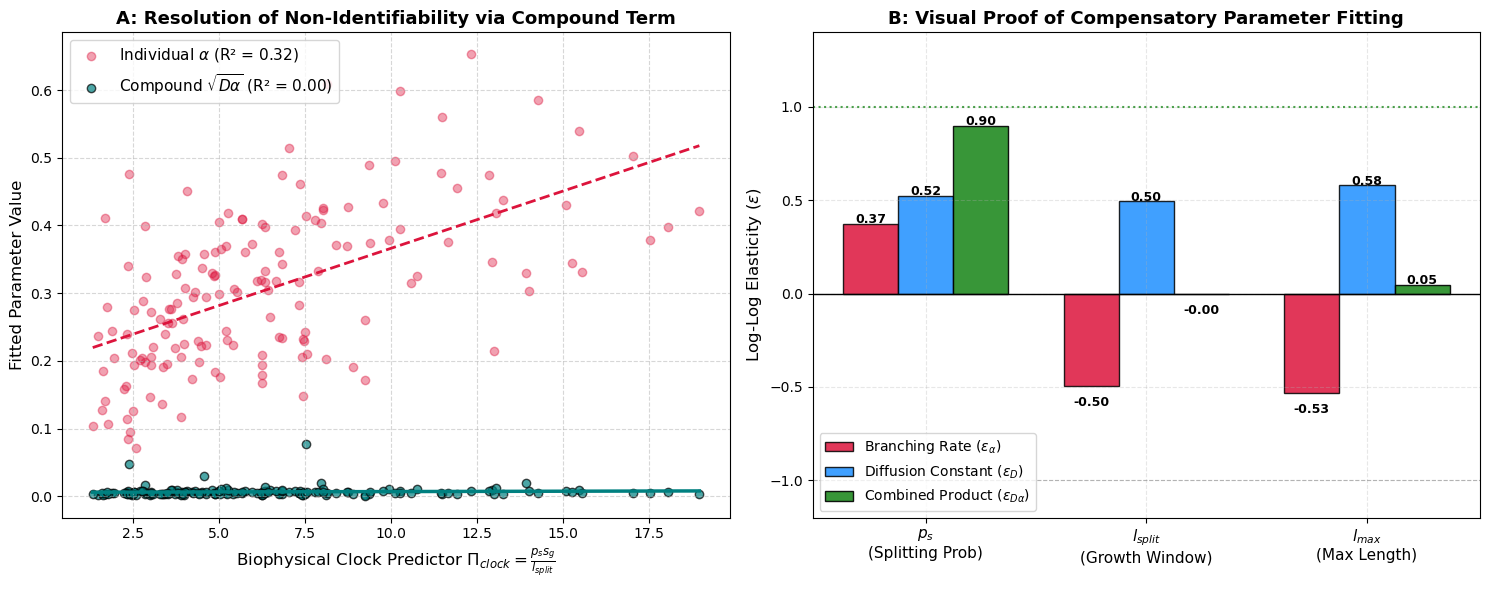

In [35]:
# =====================================================================
# RENEWAL THEORY & DEGENERACY VALIDATION SUITE (UPDATED)
# =====================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# 1. Define the biophysical components from the dataframe
growth_window = in_out['split_l'] 
p_s = in_out['s_p']
s_g = in_out['sg']
alpha = in_out['alpha']
D = in_out['D']
D_alpha = D * alpha  # Combined transport-reaction product

# 2. Calculate Empirical Log-Log Elasticities for alpha, D, and D*alpha
inputs_to_test = {'s_p': p_s, 'split_l': growth_window, 'max_l': in_out['max_l']}
elasticities = {var: {} for var in ['alpha', 'D', 'D_alpha']}

for name, x_data in inputs_to_test.items():
    # Elasticity for alpha
    slope_a, _, _, _, _ = stats.linregress(np.log(x_data), np.log(alpha))
    elasticities['alpha'][name] = slope_a
    
    # Elasticity for D
    slope_D, _, _, _, _ = stats.linregress(np.log(x_data), np.log(D))
    elasticities['D'][name] = slope_D
    
    # Elasticity for the compound product D*alpha
    slope_Da, _, _, _, _ = stats.linregress(np.log(x_data), np.log(D_alpha))
    elasticities['D_alpha'][name] = slope_Da

# 3. Perform Regressions for the individual vs compound terms
# If the front speed selected is c ~ vd + 2*sqrt(D*alpha), then sqrt(D*alpha) represents 
# the reactive-diffusive velocity component of front propagation.
sqrt_D_alpha = np.sqrt(D_alpha)
in_out['Pi_clock_window'] = (p_s * s_g) / growth_window

slope_ind, inter_ind, r_ind, _, _ = stats.linregress(in_out['Pi_clock_window'], alpha)
slope_comp, inter_comp, r_comp, _, _ = stats.linregress(in_out['Pi_clock_window'], sqrt_D_alpha)


# 4. Generate the Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Panel A: Showing how the compound term resolves the poor individual fit
ax1.scatter(in_out['Pi_clock_window'], alpha, color='crimson', alpha=0.4, label=r'Individual $\alpha$ (R² = ' + f'{r_ind**2:.2f})')
ax1.scatter(in_out['Pi_clock_window'], sqrt_D_alpha, color='teal', alpha=0.7, edgecolors='k', label=r'Compound $\sqrt{D\alpha}$ (R² = ' + f'{r_comp**2:.2f})')

# Add trendlines
fit_x = np.linspace(in_out['Pi_clock_window'].min(), in_out['Pi_clock_window'].max(), 100)
ax1.plot(fit_x, slope_ind * fit_x + inter_ind, color='crimson', linestyle='--', lw=2)
ax1.plot(fit_x, slope_comp * fit_x + inter_comp, color='teal', lw=2.5)

ax1.set_xlabel(r'Biophysical Clock Predictor $\Pi_{clock} = \frac{p_s s_g}{l_{split}}$', fontsize=12)
ax1.set_ylabel('Fitted Parameter Value', fontsize=12)
ax1.set_title('A: Resolution of Non-Identifiability via Compound Term', fontsize=13, weight='bold')
ax1.legend(fontsize=11, loc='upper left')
ax1.grid(True, linestyle='--', alpha=0.5)


# Panel B: Visual Proof of Compensatory Elasticities (The Degeneracy)
labels = [r'$p_s$' + '\n(Splitting Prob)', r'$l_{split}$' + '\n(Growth Window)', r'$l_{max}$' + '\n(Max Length)']
alpha_vals = [elasticities['alpha']['s_p'], elasticities['alpha']['split_l'], elasticities['alpha']['max_l']]
D_vals = [elasticities['D']['s_p'], elasticities['D']['split_l'], elasticities['D']['max_l']]
combined_vals = [elasticities['D_alpha']['s_p'], elasticities['D_alpha']['split_l'], elasticities['D_alpha']['max_l']]

x = np.arange(len(labels))
width = 0.25

# Plot bars
rects1 = ax2.bar(x - width, alpha_vals, width, label=r'Branching Rate ($\epsilon_{\alpha}$)', color='crimson', alpha=0.85, edgecolor='k')
rects2 = ax2.bar(x, D_vals, width, label=r'Diffusion Constant ($\epsilon_{D}$)', color='dodgerblue', alpha=0.85, edgecolor='k')
rects3 = ax2.bar(x + width, combined_vals, width, label=r'Combined Product ($\epsilon_{D\alpha}$)', color='forestgreen', alpha=0.9, edgecolor='k')

# Add horizontal guides for theoretical targets
ax2.axhline(1.0, color='forestgreen', linestyle=':', linewidth=1.5, alpha=0.8)
ax2.axhline(0.0, color='black', linewidth=1.0)
ax2.axhline(-1.0, color='grey', linestyle='--', linewidth=0.8, alpha=0.5)

# Add text labels on the bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        va_dir = 'bottom' if height >= 0 else 'top'
        offset = 0.03 if height >= 0 else -0.12
        ax2.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3 if height >= 0 else -12),  # vertical offset in points
                    textcoords="offset points",
                    ha='center', va='center', fontweight='bold', fontsize=9)

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

# Style Panel B
ax2.set_ylabel('Log-Log Elasticity ($\epsilon$)', fontsize=12)
ax2.set_title('B: Visual Proof of Compensatory Parameter Fitting', fontsize=13, weight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=11)
ax2.legend(fontsize=10, loc='lower left')
ax2.grid(True, linestyle='--', alpha=0.3)
ax2.set_ylim(-1.2, 1.4)

plt.tight_layout()
plt.savefig('degeneracy_and_clock_proof.png', dpi=300)
plt.show()


  REVISED PERSISTENT RANDOM WALK TEST (RAW SIMULATION DATA)  
Test 1: Do D and alpha scale with tip speed? (D*alpha vs. sg²)
  - R² correlation: 0.0027
  - p-value:        5.18e-01
  - Fitted Slope:   -0.0044
------------------------------------------------------------
Test 2: Does D scale with persistence? (D vs. sg² / alpha)
  - R² correlation: 0.0102
  - p-value:        2.06e-01
  - Fitted Slope:   -0.0068
  MULTIVARIABLE OLS REGRESSION SUMMARY FOR RAW ln(D)  
                            OLS Regression Results                            
Dep. Variable:                      D   R-squared:                       0.103
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     2.463
Date:                Thu, 13 Aug 2026   Prob (F-statistic):             0.0203
Time:                        11:44:29   Log-Likelihood:                -216.90
No. Observations:                 158   AIC:             

<>:60: SyntaxWarning: invalid escape sequence '\p'
<>:69: SyntaxWarning: invalid escape sequence '\p'
<>:60: SyntaxWarning: invalid escape sequence '\p'
<>:69: SyntaxWarning: invalid escape sequence '\p'
/var/folders/nv/8htcvdk16flcwrc093r8v2v00000gp/T/ipykernel_43571/2870951270.py:60: SyntaxWarning: invalid escape sequence '\p'
  ax1.set_title('Raw Scaling: $D\\alpha \propto s_g^2$', fontsize=13, weight='bold')
/var/folders/nv/8htcvdk16flcwrc093r8v2v00000gp/T/ipykernel_43571/2870951270.py:69: SyntaxWarning: invalid escape sequence '\p'
  ax2.set_title('Raw Scaling: $D$ \propto s_g^2 / \alpha$', fontsize=13, weight='bold')
/var/folders/nv/8htcvdk16flcwrc093r8v2v00000gp/T/ipykernel_43571/2870951270.py:72: UserWarning: Glyph 7 () missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/envs/bmxfungi/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 7 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


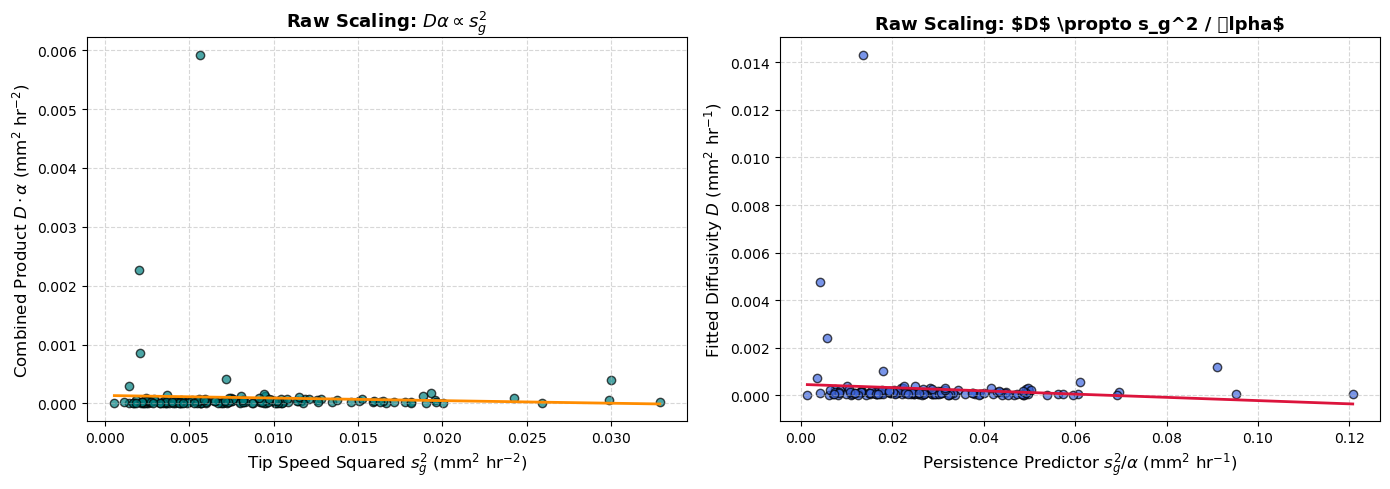

In [40]:
# =====================================================================
# RAW SIMULATED DATA DIAGNOSTIC SUITE
# =====================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

# 1. Calculate the physical variables on the raw 158 simulations
raw_data = in_out.copy()
raw_data['D_times_alpha'] = raw_data['D'] * raw_data['alpha']
raw_data['sg_squared'] = raw_data['sg'] ** 2
raw_data['l_avg'] = raw_data['max_l'] - 0.5 * raw_data['split_l']

# 2. Test the Revised PRW Scaling: D * alpha vs. sg^2
slope_prw, inter_prw, r_prw, p_prw, se_prw = stats.linregress(raw_data['sg_squared'], raw_data['D_times_alpha'])

# 3. Test the direct correlation between D and sg^2 / alpha
raw_data['sg2_over_alpha'] = raw_data['sg_squared'] / raw_data['alpha']
slope_inv, inter_inv, r_inv, p_inv, se_inv = stats.linregress(raw_data['sg2_over_alpha'], raw_data['D'])

# 4. Run a formal Ordinary Least Squares (OLS) Multivariable Regression on raw ln(D)
# This will show us which parameters are actually statistically significant in the raw data
inputs = ['max_l', 'split_l', 'max_r', 's_p', 'f_p', 'f_separation', 'W_A']
X_raw = np.log(raw_data[inputs])
X_raw = sm.add_constant(X_raw)  # Add intercept
Y_raw = np.log(raw_data['D'])

ols_model = sm.OLS(Y_raw, X_raw).fit()

# 5. Display the Statistical Summaries
print("\n" + "="*60)
print("  REVISED PERSISTENT RANDOM WALK TEST (RAW SIMULATION DATA)  ")
print("="*60)
print(f"Test 1: Do D and alpha scale with tip speed? (D*alpha vs. sg²)")
print(f"  - R² correlation: {r_prw**2:.4f}")
print(f"  - p-value:        {p_prw:.2e}")
print(f"  - Fitted Slope:   {slope_prw:.4f}")
print("-" * 60)
print(f"Test 2: Does D scale with persistence? (D vs. sg² / alpha)")
print(f"  - R² correlation: {r_inv**2:.4f}")
print(f"  - p-value:        {p_inv:.2e}")
print(f"  - Fitted Slope:   {slope_inv:.4f}")
print("="*60)
print("  MULTIVARIABLE OLS REGRESSION SUMMARY FOR RAW ln(D)  ")
print("="*60)
print(ols_model.summary())
print("="*60)

# 6. Plot the Raw Relationships
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: D*alpha vs sg^2
ax1.scatter(raw_data['sg_squared'], raw_data['D_times_alpha'], color='teal', alpha=0.7, edgecolors='k')
fit_x = np.linspace(raw_data['sg_squared'].min(), raw_data['sg_squared'].max(), 100)
ax1.plot(fit_x, slope_prw * fit_x + inter_prw, color='darkorange', lw=2)
ax1.set_xlabel(r'Tip Speed Squared $s_g^2$ (mm$^2$ hr$^{-2}$)', fontsize=12)
ax1.set_ylabel(r'Combined Product $D\cdot\alpha$ (mm$^2$ hr$^{-2}$)', fontsize=12)
ax1.set_title('Raw Scaling: $D\\alpha \propto s_g^2$', fontsize=13, weight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot 2: D vs sg^2 / alpha
ax2.scatter(raw_data['sg2_over_alpha'], raw_data['D'], color='royalblue', alpha=0.7, edgecolors='k')
fit_x2 = np.linspace(raw_data['sg2_over_alpha'].min(), raw_data['sg2_over_alpha'].max(), 100)
ax2.plot(fit_x2, slope_inv * fit_x2 + inter_inv, color='crimson', lw=2)
ax2.set_xlabel(r'Persistence Predictor $s_g^2 / \alpha$ (mm$^2$ hr$^{-1}$)', fontsize=12)
ax2.set_ylabel(r'Fitted Diffusivity $D$ (mm$^2$ hr$^{-1}$)', fontsize=12)
ax2.set_title('Raw Scaling: $D$ \propto s_g^2 / \alpha$', fontsize=13, weight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


  DRIFT VELOCITY & STERIC FRICTION TEST (RAW DATA)  
Steric Crowding Regression (Fractional Drift Loss vs. r_max * rho_sat):
  - R² correlation: 0.0127
  - p-value:        1.58e-01
  - Fitted Slope:   0.0678 (Expected: > 0 if crowding causes drag)
  - Intercept:      0.7890
------------------------------------------------------------
Target Elasticities on Raw Data:
  - Measured Elasticity of vd to max_r (ε_vd,rmax): -0.4278 (Expected: < 0)
  - Measured Elasticity of vd to sg (ε_vd,sg):      0.4284 (Expected: ≈ 1.0)
  MULTIVARIABLE OLS REGRESSION SUMMARY FOR RAW ln(v_d)  
                            OLS Regression Results                            
Dep. Variable:                     vd   R-squared:                       0.176
Model:                            OLS   Adj. R-squared:                  0.137
Method:                 Least Squares   F-statistic:                     4.564
Date:                Thu, 13 Aug 2026   Prob (F-statistic):           0.000120
Time:                    

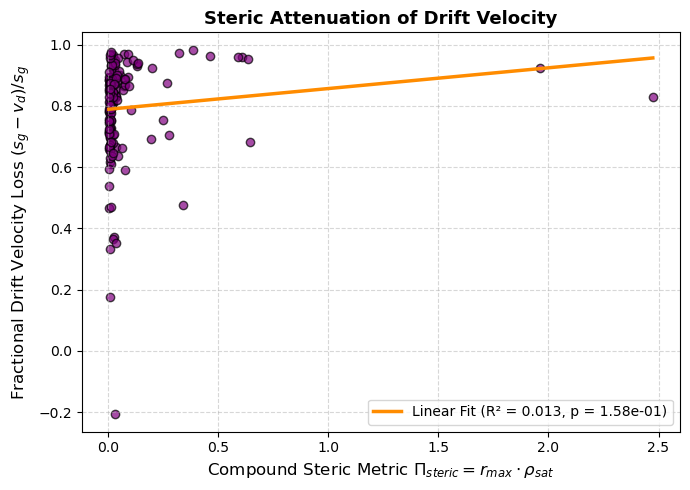

In [41]:
# =====================================================================
# RAW SIMULATED DATA: DRIFT AND STERIC FRICTION TEST
# =====================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

# 1. Calculate the steric variables on the raw 158 simulations
drift_data = in_out.copy()
# Ensure rho (saturation density) is calculated
drift_data['rho_sat'] = 2.0 * drift_data['alpha'] / drift_data['beta']

# Calculate the fractional loss of drift velocity: (s_g - v_d) / s_g
drift_data['fractional_drift_loss'] = (drift_data['sg'] - drift_data['vd']) / drift_data['sg']

# Calculate the compound steric metric: r_max * rho_sat
drift_data['Pi_steric'] = drift_data['max_r'] * drift_data['rho_sat']

# 2. Regression: Fractional Drift Loss vs. Compound Steric Metric
slope_st, inter_st, r_st, p_st, se_st = stats.linregress(drift_data['Pi_steric'], drift_data['fractional_drift_loss'])

# 3. Direct Elasticity: vd vs. max_r
slope_eps_rmax, _, _, _, _ = stats.linregress(np.log(drift_data['max_r']), np.log(drift_data['vd']))

# 4. Direct Elasticity: vd vs. sg (how drift scales with active tip elongation speed)
slope_eps_sg, _, _, _, _ = stats.linregress(np.log(drift_data['sg']), np.log(drift_data['vd']))

# 5. Multivariable OLS Regression on raw ln(v_d) to see steric predictors
inputs_vd = ['max_l', 'split_l', 'max_r', 's_p', 'f_p', 'f_separation', 'W_A']
X_vd = np.log(drift_data[inputs_vd])
X_vd = sm.add_constant(X_vd)
Y_vd = np.log(drift_data['vd'])

ols_vd_model = sm.OLS(Y_vd, X_vd).fit()

# 6. Display the Results
print("\n" + "="*60)
print("  DRIFT VELOCITY & STERIC FRICTION TEST (RAW DATA)  ")
print("="*60)
print(f"Steric Crowding Regression (Fractional Drift Loss vs. r_max * rho_sat):")
print(f"  - R² correlation: {r_st**2:.4f}")
print(f"  - p-value:        {p_st:.2e}")
print(f"  - Fitted Slope:   {slope_st:.4f} (Expected: > 0 if crowding causes drag)")
print(f"  - Intercept:      {inter_st:.4f}")
print("-" * 60)
print(f"Target Elasticities on Raw Data:")
print(f"  - Measured Elasticity of vd to max_r (ε_vd,rmax): {slope_eps_rmax:.4f} (Expected: < 0)")
print(f"  - Measured Elasticity of vd to sg (ε_vd,sg):      {slope_eps_sg:.4f} (Expected: ≈ 1.0)")
print("="*60)
print("  MULTIVARIABLE OLS REGRESSION SUMMARY FOR RAW ln(v_d)  ")
print("="*60)
print(ols_vd_model.summary())
print("="*60)

# 7. Plot the Steric Crowding Relationship
plt.figure(figsize=(7, 5))
plt.scatter(drift_data['Pi_steric'], drift_data['fractional_drift_loss'], color='purple', alpha=0.7, edgecolors='k')
fit_x = np.linspace(drift_data['Pi_steric'].min(), drift_data['Pi_steric'].max(), 100)
plt.plot(fit_x, slope_st * fit_x + inter_st, color='darkorange', lw=2.5, 
         label=f'Linear Fit (R² = {r_st**2:.3f}, p = {p_st:.2e})')
plt.xlabel(r'Compound Steric Metric $\Pi_{steric} = r_{max} \cdot \rho_{sat}$', fontsize=12)
plt.ylabel(r'Fractional Drift Velocity Loss $(s_g - v_d)/s_g$', fontsize=12)
plt.title('Steric Attenuation of Drift Velocity', fontsize=13, weight='bold')
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

slope:-0.12034266463897833
r-squared:0.002357959427996618
p value:0.5511314407207751


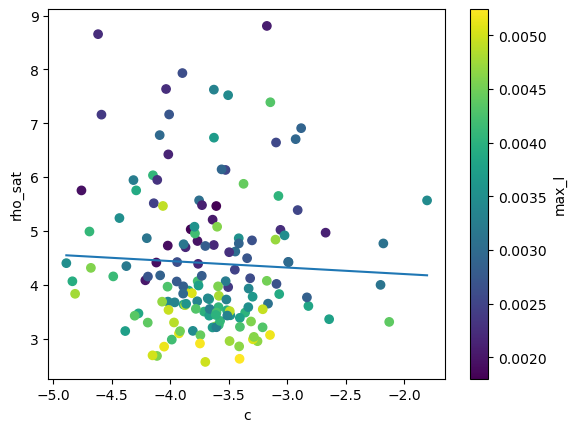

In [15]:
plot1 = 'c'
plot2 = 'rho_sat'
color = 'max_l'
fig, ax = plt.subplots()
cm = plt.get_cmap('RdYlBu')
sc = ax.scatter(np.log(in_out[plot1]), np.log(in_out[plot2]), c = in_out[color]) # , s = (PDE_mn_df['error'] + 0.5) * 10)
res = stats.linregress(np.log(in_out[plot1]), np.log(in_out[plot2]))
print(f'slope:{res.slope}')
print(f'r-squared:{(res.rvalue) ** 2}')
print(f'p value:{res.pvalue}')
x = np.linspace(np.min(np.log(in_out[plot1])), np.max(np.log(in_out[plot1])), 100)
ax.plot(x, (x * res.slope) + res.intercept)
ax.set_xlabel(plot1)
ax.set_ylabel(plot2)
# ax.set_xscale('log')
# ax.set_yscale('log')
fig.colorbar(sc, ax=ax, label = color)
# plt.savefig('rho_c_beta.png')

slope:-0.12034266463897833
r-squared:0.002357959427996618
p value:0.5511314407207751


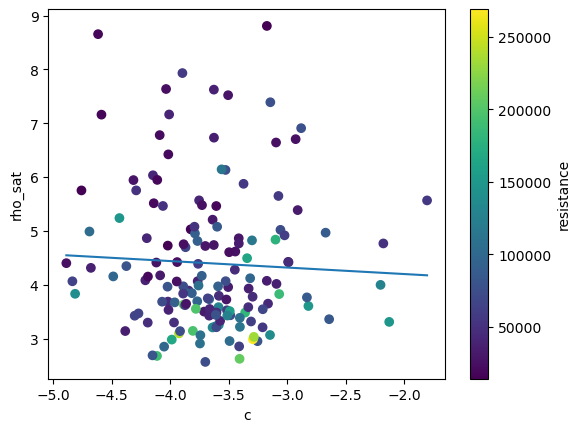

In [16]:
plot1 = 'c'
plot2 = 'rho_sat'
color = 'resistance'
fig, ax = plt.subplots()
cm = plt.get_cmap('RdYlBu')
sc = ax.scatter(np.log(in_out[plot1]), np.log(in_out[plot2]), c = in_out[color]) # , s = (PDE_mn_df['error'] + 0.5) * 10)
res = stats.linregress(np.log(in_out[plot1]), np.log(in_out[plot2]))
print(f'slope:{res.slope}')
print(f'r-squared:{(res.rvalue) ** 2}')
print(f'p value:{res.pvalue}')
x = np.linspace(np.min(np.log(in_out[plot1])), np.max(np.log(in_out[plot1])), 100)
ax.plot(x, (x * res.slope) + res.intercept)
ax.set_xlabel(plot1)
ax.set_ylabel(plot2)
# ax.set_xscale('log')
# ax.set_yscale('log')
fig.colorbar(sc, ax=ax, label = color)
# plt.savefig('rho_c_beta.png')

In [17]:
# fig2, ax2 = plt.subplots(7, 2, figsize = (16, 56))
# for par in np.arange(len(params)):
#     hist_list = []
#     for n in list_n:
#         p = run_params[n]
#         ax2[par,0].plot(n, float(p[par]), 'y.')
#         hist_list.append(float(p[par]))
#     ax2[par,1].hist(hist_list, bins = 20)
#     ax2[par,0].set_title(params[par])
#     ax2[par,1].set_title(params[par])
#     for tick in ax2[par,1].get_xticklabels():
#         tick.set_rotation(45)
# plt.tight_layout()
# plt.savefig('IBM_dist.png')

### Simulated Data

In [15]:
with open('/Users/laurenyan/bmxfungi_surrogate/rbf_pickles/alpha_mn_rbf.pkl', 'rb') as f:
    alpha_mn_rbf = dill.load(f)
with open('/Users/laurenyan/bmxfungi_surrogate/rbf_pickles/beta_mn_rbf.pkl', 'rb') as f:
    beta_mn_rbf = dill.load(f)
with open('/Users/laurenyan/bmxfungi_surrogate/rbf_pickles/vd_mn_rbf.pkl', 'rb') as f:
    vd_mn_rbf = dill.load(f)
with open('/Users/laurenyan/bmxfungi_surrogate/rbf_pickles/sg_mn_rbf.pkl', 'rb') as f:
    sg_mn_rbf = dill.load(f)
with open('/Users/laurenyan/bmxfungi_surrogate/rbf_pickles/D_mn_rbf.pkl', 'rb') as f:
    D_mn_rbf = dill.load(f)

with open('/Users/laurenyan/bmxfungi_surrogate/rbf_pickles/alpha_lb_rbf.pkl', 'rb') as f:
    alpha_lb_rbf = dill.load(f)
with open('/Users/laurenyan/bmxfungi_surrogate/rbf_pickles/beta_lb_rbf.pkl', 'rb') as f:
    beta_lb_rbf = dill.load(f)
with open('/Users/laurenyan/bmxfungi_surrogate/rbf_pickles/vd_lb_rbf.pkl', 'rb') as f:
    vd_lb_rbf = dill.load(f)
with open('/Users/laurenyan/bmxfungi_surrogate/rbf_pickles/sg_lb_rbf.pkl', 'rb') as f:
    sg_lb_rbf = dill.load(f)
with open('/Users/laurenyan/bmxfungi_surrogate/rbf_pickles/D_lb_rbf.pkl', 'rb') as f:
    D_lb_rbf = dill.load(f)

with open('/Users/laurenyan/bmxfungi_surrogate/rbf_pickles/alpha_ub_rbf.pkl', 'rb') as f:
    alpha_ub_rbf = dill.load(f)
with open('/Users/laurenyan/bmxfungi_surrogate/rbf_pickles/beta_ub_rbf.pkl', 'rb') as f:
    beta_ub_rbf = dill.load(f)
with open('/Users/laurenyan/bmxfungi_surrogate/rbf_pickles/vd_ub_rbf.pkl', 'rb') as f:
    vd_ub_rbf = dill.load(f)
with open('/Users/laurenyan/bmxfungi_surrogate/rbf_pickles/sg_ub_rbf.pkl', 'rb') as f:
    sg_ub_rbf = dill.load(f)
with open('/Users/laurenyan/bmxfungi_surrogate/rbf_pickles/D_ub_rbf.pkl', 'rb') as f:
    D_ub_rbf = dill.load(f)

In [16]:
# headers = ['sim_name', 'alpha', 'beta', 'vd', 'sg', 'D', 'A', 's', 'r0']
# initial_guess = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/constantguess.csv', header=None, names=headers)
# upar = [initial_guess['A'].mean(), initial_guess['s'].mean(), initial_guess['r0'].mean()]

In [17]:
# SA_in = {
#     'num_vars': 7,
#     'names': ['max_l', 'split_l', 'max_r', 's_p', 'f_p', 'f_separation', 'W_A'],
#     'bounds': [[17.5e-4, 52.5e-4], [2.5e-4, 7.5e-4], [1.25e-4, 3.75e-4], [0.1, 0.3], [0.005, 0.015], [3.0e-4, 9.0e-4], [0.5e-4, 1.5e-4]]
# }
SA_in = {
    'num_vars': 7,
    'names': ['max_l', 'split_l', 'max_r', 's_p', 'f_p', 'f_separation', 'W_A'],
    'bounds': [[np.min(ABM_sample[:, 0]) * 1.2, np.max(ABM_sample[:, 0]) * 0.8],
               [(np.min(ABM_sample[:, 0] - ABM_sample[:, 1])) * 1.2, (np.max(ABM_sample[:, 0] - ABM_sample[:, 1])) * 0.8],
               [np.min(ABM_sample[:, 2]) * 1.2, np.max(ABM_sample[:, 2]) * 0.8],
               [np.min(ABM_sample[:, 3]) * 1.2, np.max(ABM_sample[:, 3]) * 0.8],
               [np.min(ABM_sample[:, 4]) * 1.2, np.max(ABM_sample[:, 4]) * 0.8],
               [np.min(ABM_sample[:, 5]) * 1.2, np.max(ABM_sample[:, 5]) * 0.8],
               [np.min(ABM_sample[:, 6]) * 1.2, np.max(ABM_sample[:, 6]) * 0.8]]
}

In [18]:
# ABM_in = saltelli.sample(SA_in, 1024)
ABM_in = latin.sample(SA_in, 2000, seed = 25)
ABM_in[:, 1] = ABM_in[:, 0] - ABM_in[:, 1] # split length is sampled as the difference between split length and maximum length
ABM_in_norm = ABM_scaler.transform(ABM_in)

In [19]:
ABM_in_df = pd.DataFrame(ABM_in, columns = ['max_l', 'split_l', 'max_r', 's_p', 'f_p', 'f_separation', 'W_A'])
ABM_in_df.to_csv('ABM_in.csv')

In [20]:
PDE_in_mn = mn_scaler.inverse_transform(np.column_stack((alpha_mn_rbf(ABM_in_norm),
                        beta_mn_rbf(ABM_in_norm),
                        vd_mn_rbf(ABM_in_norm),
                        sg_mn_rbf(ABM_in_norm),
                        D_mn_rbf(ABM_in_norm))))
PDE_in_mn = np.column_stack((PDE_in_mn,
                             2 * PDE_in_mn[:, 0] / PDE_in_mn[:, 1], 
                             PDE_in_mn[:, 2] + 2 * np.sqrt(PDE_in_mn[:, 4] * PDE_in_mn[:, 0])))
PDE_in_lb = lb_scaler.inverse_transform(np.column_stack((alpha_lb_rbf(ABM_in_norm),
                        beta_lb_rbf(ABM_in_norm),
                        vd_lb_rbf(ABM_in_norm),
                        sg_lb_rbf(ABM_in_norm),
                        D_lb_rbf(ABM_in_norm))))
PDE_in_lb = np.column_stack((PDE_in_lb,
                             2 * PDE_in_lb[:, 0] / PDE_in_lb[:, 1], 
                             PDE_in_lb[:, 2] + 2 * np.sqrt(PDE_in_lb[:, 4] * PDE_in_lb[:, 0])))
PDE_in_ub = ub_scaler.inverse_transform(np.column_stack((alpha_ub_rbf(ABM_in_norm),
                        beta_ub_rbf(ABM_in_norm),
                        vd_ub_rbf(ABM_in_norm),
                        sg_ub_rbf(ABM_in_norm),
                        D_ub_rbf(ABM_in_norm))))
PDE_in_ub = np.column_stack((PDE_in_ub,
                             2 * PDE_in_ub[:, 0] / PDE_in_ub[:, 1], 
                             PDE_in_ub[:, 2] + 2 * np.sqrt(PDE_in_ub[:, 4] * PDE_in_ub[:, 0])))

Text(0.5, 1.0, 'PDE interpolation')

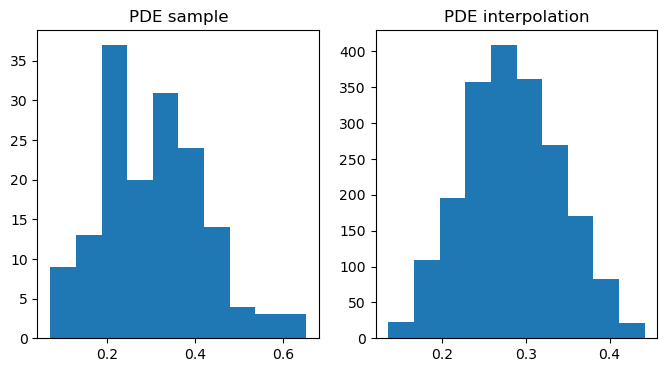

In [21]:
i = 0
fig, ax = plt.subplots(1,2, figsize = (8, 4))
ax[0].hist(PDE_mn[:, i])
ax[0].set_title('PDE sample')
ax[1].hist(PDE_in_mn[:, i])
ax[1].set_title('PDE interpolation')

In [22]:
PDE_in_mn[PDE_in_mn < 0]
PDE_in_lb[PDE_in_lb < 0]
PDE_in_ub[PDE_in_ub < 0]

array([], dtype=float64)

In [23]:
j = 1
PDE_in_mn[:, j][PDE_in_mn[:, j] < 0]
PDE_in_ub[:, j][PDE_in_ub[:, j] < 0]
PDE_in_lb[:, j][PDE_in_lb[:, j] < 0]

array([], dtype=float64)

In [24]:
# PDE_in_mn[(PDE_in_mn < 0).any(axis=1)]

In [25]:
# ABM_in[(PDE_in_mn < 0).any(axis=1)]

In [26]:
# PDE_in_mn[:, 0:5][PDE_in_mn[:, 0:5] < 0] = 1e-2
# PDE_in_lb[:, 0:5][PDE_in_lb[:, 0:5] < 0] = 1e-2
# PDE_in_ub[:, 0:5][PDE_in_ub[:, 0:5] < 0] = 1e-2

# PDE_in_mn[:, 5] = 2 * PDE_in_mn[:, 0] / PDE_in_mn[:, 1]
# PDE_in_lb[:, 5] = 2 * PDE_in_lb[:, 0] / PDE_in_lb[:, 1]
# PDE_in_ub[:, 5] = 2 * PDE_in_ub[:, 0] / PDE_in_ub[:, 1]

# PDE_in_mn[:, 6] = PDE_in_mn[:, 2] + 2 * np.sqrt(PDE_in_mn[:, 4] * PDE_in_mn[:, 0])
# PDE_in_lb[:, 6] = PDE_in_lb[:, 2] + 2 * np.sqrt(PDE_in_lb[:, 4] * PDE_in_lb[:, 0])
# PDE_in_ub[:, 6] = PDE_in_ub[:, 2] + 2 * np.sqrt(PDE_in_ub[:, 4] * PDE_in_ub[:, 0])

In [27]:
PDE_in_mn_df = pd.DataFrame(PDE_in_mn,columns = ['alpha', 'beta', 'vd', 'sg', 'D', 'rho_sat', 'c'])
PDE_in_mn_df.to_csv('PDE_in_mn.csv')

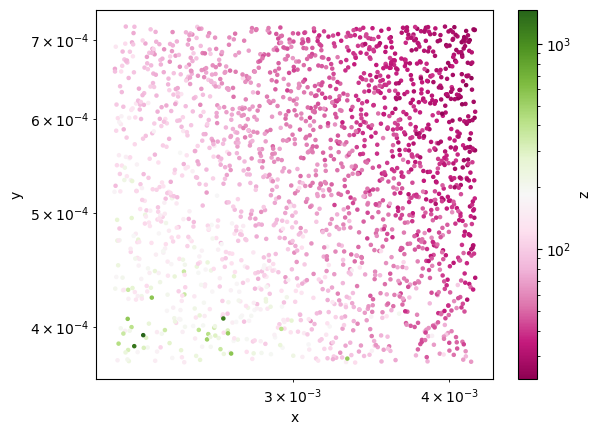

In [28]:
fig, ax = plt.subplots()
cm = plt.get_cmap('PiYG')
sc = ax.scatter(ABM_in[:, 0], ABM_in[:, 5], c = PDE_in_mn[:, 5], s = 5, cmap = cm, norm=matplotlib.colors.LogNorm())
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_xscale('log')
ax.set_yscale('log')
cbar = plt.colorbar(sc, ax=ax, label = 'z')

In [29]:
mask_low = np.ones(2000, dtype=bool)
mask_low[PDE_in_mn[:, 5] > 300] = False
print(np.shape(PDE_in_mn[mask_low]))

mask_high = np.ones(2000, dtype=bool)
mask_high[PDE_in_mn[:, 5] < 300] = False
print(np.shape(PDE_in_mn[mask_high]))

(1977, 7)
(23, 7)


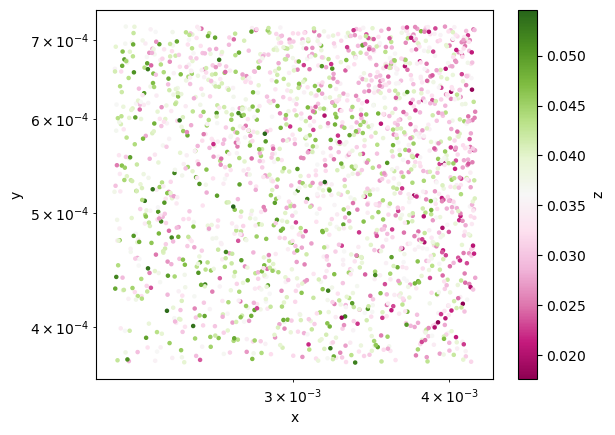

In [30]:
fig, ax = plt.subplots()
cm = plt.get_cmap('PiYG')
sc = ax.scatter(ABM_in[mask_low][:, 0], ABM_in[mask_low][:, 5], c = PDE_in_mn[mask_low][:, 6], s = 5, cmap = cm)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_xscale('log')
ax.set_yscale('log')
cbar = plt.colorbar(sc, ax=ax, label = 'z')

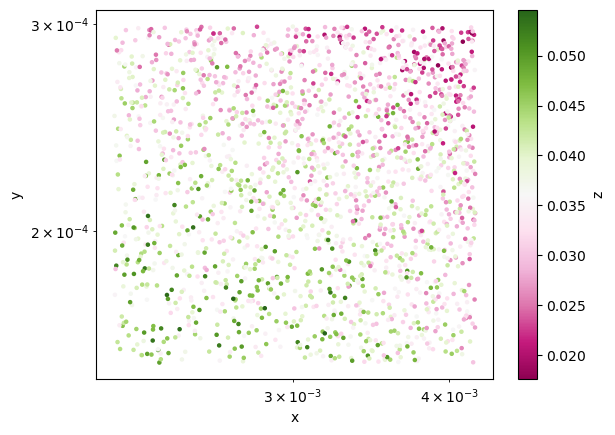

In [31]:
fig, ax = plt.subplots()
cm = plt.get_cmap('PiYG')
sc = ax.scatter(ABM_in[mask_low][:, 0], ABM_in[mask_low][:, 2], c = PDE_in_mn[mask_low][:, 6], s = 5, cmap = cm) # , norm=matplotlib.colors.LogNorm())
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_xscale('log')
ax.set_yscale('log')
cbar = plt.colorbar(sc, ax=ax, label = 'z')

In [32]:
# fig, ax = plt.subplots()
# cm = plt.get_cmap('PiYG')
# sc = ax.scatter(PDE_in_mn[:, 2], PDE_in_mn[:, 6], c = PDE_in_mn[:, 5], s = 5, cmap = cm) # , norm=matplotlib.colors.LogNorm())
# ax.set_xlabel('x')
# ax.set_ylabel('y')
# ax.set_xscale('log')
# ax.set_yscale('log')
# cbar = plt.colorbar(sc, ax=ax, label = 'z')

In [33]:
in_names = ['max_l', 'split_l', 'max_r', 's_p', 'f_p', 'f_separation', 'W_A']
i1 = 0
plot1 = in_names[i1]
i2 = 2
plot2 = in_names[i2]
i3 = 3
plot3 = in_names[i3]
i4 = 5
plot4 = in_names[i4]
rc = pd.DataFrame({plot1: ABM_in[mask_low][:, i1],
                   plot2: ABM_in[mask_low][:, i2],
                   plot3: ABM_in[mask_low][:, i3],
                   plot4: ABM_in[mask_low][:, i4],
                   'rho_sat': PDE_in_mn[mask_low][:, 5],
                   'c': PDE_in_mn[mask_low][:, 6]})

scaler = MinMaxScaler(feature_range = (1, 2))
scaler.fit(rc[['rho_sat', 'c']])
rc[['rho_sat_norm', 'c_norm']] = scaler.transform(rc[['rho_sat', 'c']])
rc['r * c'] = rc['rho_sat_norm'] * rc['c_norm']
rc['r / c'] = rc['rho_sat_norm'] / rc['c_norm']
rc['resistance'] = rc['max_l'] / (rc['max_r'] ** 2)

rc

,max_l,max_r,s_p,f_separation,rho_sat,c,rho_sat_norm,c_norm,r * c,r / c,resistance
0,0.004155,0.000170,0.174475,0.000506,30.482130,0.035464,1.026415,1.483548,1.522735,0.691865,144348.002317
1,0.002972,0.000293,0.178146,0.000679,52.211812,0.028518,1.105342,1.296217,1.432764,0.852745,34592.306478
2,0.003784,0.000206,0.129309,0.000474,43.761744,0.026739,1.074649,1.248232,1.341412,0.860937,88906.531554
3,0.003179,0.000226,0.199519,0.000383,110.473163,0.040657,1.316962,1.623588,2.138204,0.811143,62110.416125
4,0.004098,0.000246,0.176016,0.000389,53.714327,0.034699,1.110800,1.462901,1.624990,0.759313,67850.996831
...,...,...,...,...,...,...,...,...,...,...,...
1972,0.003546,0.000157,0.125148,0.000484,41.276944,0.030191,1.065624,1.341341,1.429365,0.794447,143880.023776
1973,0.003788,0.000263,0.205028,0.000551,42.865587,0.032711,1.071394,1.409289,1.509905,0.760237,54954.357547
1974,0.003845,0.000228,0.209169,0.000633,32.839698,0.034998,1.034978,1.470959,1.522410,0.703608,73854.036388
1975,0.003374,0.000207,0.145782,0.000568,41.575418,0.030836,1.066708,1.358744,1.449384,0.785069,78477.411946


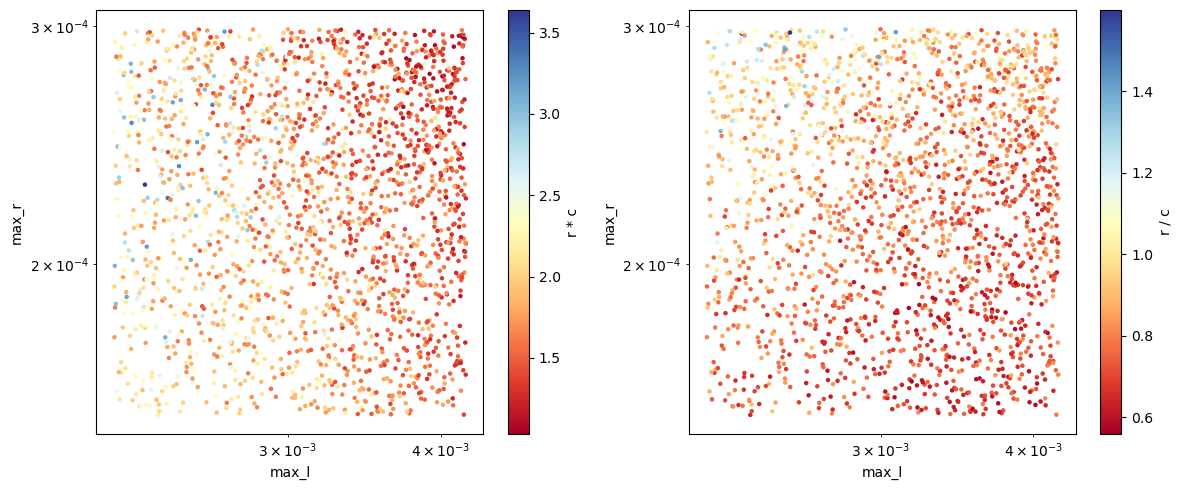

In [34]:
fig, axs = plt.subplots(1, 2, figsize = (12, 5))
cm = plt.get_cmap('RdYlBu')
color = 'r * c'
sc = axs[0].scatter(rc[plot1], rc[plot2], c = rc[color], s = 5, cmap = cm) # , norm=matplotlib.colors.LogNorm())
axs[0].set_xlabel(plot1)
axs[0].set_ylabel(plot2)
axs[0].set_xscale('log')
axs[0].set_yscale('log')
cbar = plt.colorbar(sc, ax=axs[0], label = color)
color = 'r / c'
sc = axs[1].scatter(rc[plot1], rc[plot2], c = rc[color], s = 5, cmap = cm) # , norm=matplotlib.colors.LogNorm())
axs[1].set_xlabel(plot1)
axs[1].set_ylabel(plot2)
axs[1].set_xscale('log')
axs[1].set_yscale('log')
cbar = plt.colorbar(sc, ax=axs[1], label = color)
fig.tight_layout()

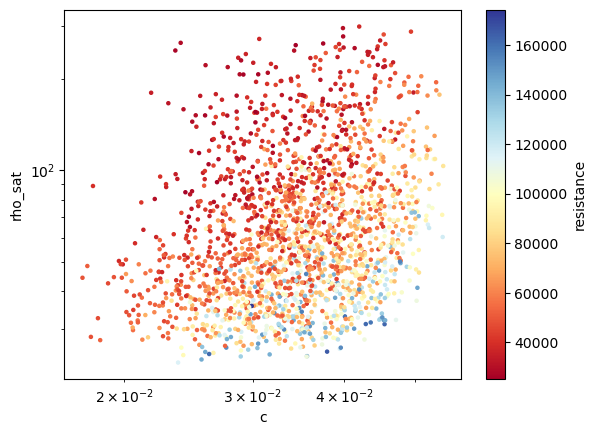

In [38]:
fig, axs = plt.subplots()
cm = plt.get_cmap('RdYlBu')
sc = axs.scatter(rc['c'], rc['rho_sat'], c = rc['resistance'], s = 5, cmap = cm) # , norm=matplotlib.colors.LogNorm())
axs.set_xlabel('c')
axs.set_ylabel('rho_sat')
axs.set_xscale('log')
axs.set_yscale('log')
cbar = plt.colorbar(sc, ax=axs, label = 'resistance')

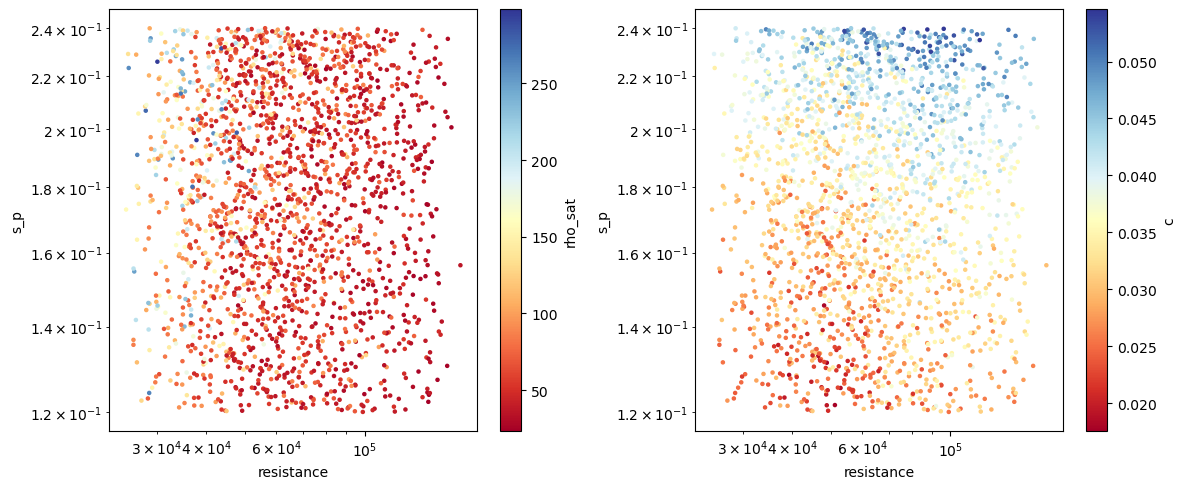

In [39]:
fig, axs = plt.subplots(1, 2, figsize = (12, 5))
p1 = 'resistance'
p2 = 's_p'
color = 'rho_sat'
cm = plt.get_cmap('RdYlBu')
sc = axs[0].scatter(rc[p1], rc[p2], c = rc[color], s = 5, cmap = cm) # , norm=matplotlib.colors.LogNorm())
axs[0].set_xlabel(p1)
axs[0].set_ylabel(p2)
axs[0].set_xscale('log')
axs[0].set_yscale('log')
cbar = plt.colorbar(sc, ax=axs[0], label = color)

color = 'c'
cm = plt.get_cmap('RdYlBu')
sc = axs[1].scatter(rc[p1], rc[p2], c = rc[color], s = 5, cmap = cm) # , norm=matplotlib.colors.LogNorm())
axs[1].set_xlabel(p1)
axs[1].set_ylabel(p2)
axs[1].set_xscale('log')
axs[1].set_yscale('log')
cbar = plt.colorbar(sc, ax=axs[1], label = color)

plt.tight_layout()

In [40]:
labels = {
    str(i): ABM_input
    for i, ABM_input in enumerate([plot1, plot2, plot3, plot4])
}

fig = px.scatter_matrix(
    rc[[plot1, plot2, plot3, plot4]].to_numpy(),
    labels=labels,
    dimensions=range(4),
    color=rc['r * c']
)
fig.update_traces(diagonal_visible=False)
import plotly.io as pio
pio.renderers.default = 'iframe'
fig.update_layout(width=1100, height=700)
fig.update_coloraxes(colorbar_title_text=r'$\rho_{sat} * c$')
fig.show()

In [41]:
labels = {
    str(i): ABM_input
    for i, ABM_input in enumerate([plot1, plot2, plot3, plot4])
}

fig = px.scatter_matrix(
    rc[[plot1, plot2, plot3, plot4]].to_numpy(),
    labels=labels,
    dimensions=range(4),
    color=rc['r / c']
)
fig.update_traces(diagonal_visible=False)
import plotly.io as pio
pio.renderers.default = 'iframe'
fig.update_layout(width=1100, height=700)
fig.update_coloraxes(colorbar_title_text=r'$\rho_{sat} / c$')
fig.show()

In [42]:
rc_tradeoff = rc[(rc['r * c'] >= 2) & (rc['r * c'] <= 2.25)]

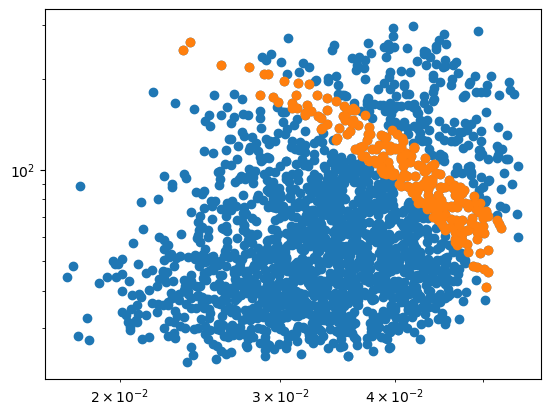

In [43]:
fig, ax = plt.subplots()
ax.scatter(rc['c'], rc['rho_sat'])
ax.scatter(rc_tradeoff['c'], rc_tradeoff['rho_sat'])
ax.set_xscale('log')
ax.set_yscale('log')

In [35]:
def evaluate_PDE_par(best, upper, lower, i):
    bul = [best, upper, lower]
    if i < 5:
        return np.mean((best[i], upper[i], lower[i]))
    
    else:
        rho_sat = []
        c = []
        alphas = [best[0], upper[0], lower[0]]
        betas = [best[1], upper[1], lower[1]]
        vds = [best[2], upper[2], lower[2]]
        Ds = [best[4], upper[4], lower[4]]
        ab, ba = np.meshgrid(alphas, betas, indexing='ij')
        vad = np.meshgrid(vds, alphas, Ds, indexing = 'ij') 
        ab_cartesian = np.stack([ab.ravel(), ba.ravel()], axis=-1)
        vad_cartesian = np.stack(vad, axis=-1).reshape(-1, 3)
        for ab in ab_cartesian:
            rho_sat.append(2 * ab[0] / ab[1])
        for vad in vad_cartesian:
            c.append(vad[0] + 2 * np.sqrt(vad[1] * vad[2]))

        if i == 5:
            return np.mean(rho_sat)
        if i == 6:
            return np.mean(c)

In [36]:
SA_in = {
    'num_vars': 7,
    'names': ['max_l', 'split_l', 'max_r', 's_p', 'f_p', 'f_separation', 'W_A'],
    'bounds': [[np.min(ABM_sample[:, 0]) * 1.2, np.max(ABM_sample[:, 0]) * 0.8],
               [(np.min(ABM_sample[:, 0] - ABM_sample[:, 1])) * 1.2, (np.max(ABM_sample[:, 0] - ABM_sample[:, 1])) * 0.8],
               [np.min(ABM_sample[:, 2]) * 1.2, np.max(ABM_sample[:, 2]) * 0.8],
               [np.min(ABM_sample[:, 3]) * 1.2, np.max(ABM_sample[:, 3]) * 0.8],
               [np.min(ABM_sample[:, 4]) * 1.2, np.max(ABM_sample[:, 4]) * 0.8],
               [np.min(ABM_sample[:, 5]) * 1.2, np.max(ABM_sample[:, 5]) * 0.8],
               [np.min(ABM_sample[:, 6]) * 1.2, np.max(ABM_sample[:, 6]) * 0.8]]
}

ABM_in = latin.sample(SA_in, 2000, seed = 25)
ABM_in[:, 1] = ABM_in[:, 0] - ABM_in[:, 1] # split length is sampled as the difference between split length and maximum length
ABM_in_norm = ABM_scaler.transform(ABM_in)

PDE_in_mn = mn_scaler.inverse_transform(np.column_stack((alpha_mn_rbf(ABM_in_norm),
                        beta_mn_rbf(ABM_in_norm),
                        vd_mn_rbf(ABM_in_norm),
                        sg_mn_rbf(ABM_in_norm),
                        D_mn_rbf(ABM_in_norm))))
PDE_in_mn = np.column_stack((PDE_in_mn,
                             2 * PDE_in_mn[:, 0] / PDE_in_mn[:, 1], 
                             PDE_in_mn[:, 2] + 2 * np.sqrt(PDE_in_mn[:, 4] * PDE_in_mn[:, 0])))
PDE_in_lb = lb_scaler.inverse_transform(np.column_stack((alpha_lb_rbf(ABM_in_norm),
                        beta_lb_rbf(ABM_in_norm),
                        vd_lb_rbf(ABM_in_norm),
                        sg_lb_rbf(ABM_in_norm),
                        D_lb_rbf(ABM_in_norm))))
# PDE_in_lb = np.column_stack((PDE_in_lb,
#                              2 * PDE_in_lb[:, 0] / PDE_in_lb[:, 1], 
#                              PDE_in_lb[:, 2] + 2 * np.sqrt(PDE_in_lb[:, 4] * PDE_in_lb[:, 0])))
PDE_in_ub = ub_scaler.inverse_transform(np.column_stack((alpha_ub_rbf(ABM_in_norm),
                        beta_ub_rbf(ABM_in_norm),
                        vd_ub_rbf(ABM_in_norm),
                        sg_ub_rbf(ABM_in_norm),
                        D_ub_rbf(ABM_in_norm))))
# PDE_in_ub = np.column_stack((PDE_in_ub,
#                              2 * PDE_in_ub[:, 0] / PDE_in_ub[:, 1], 
#                              PDE_in_ub[:, 2] + 2 * np.sqrt(PDE_in_ub[:, 4] * PDE_in_ub[:, 0])))

in_out = ABM_in
in_out = np.column_stack((in_out, in_out[:,0] / (in_out[:,2] ** 2)))

obj_name = [r'$\alpha$', r'$\beta$', r'$v_d$', r'$s_g$', r'$D$', r'$\rho _{sat}$', r'$c$']
for j in range(len(obj_name)):
    PDE_out = np.zeros([PDE_in_mn.shape[0]])
    for i, X in enumerate(zip(PDE_in_mn, PDE_in_ub, PDE_in_lb)):
        # print(i)
        PDE_out[i] = evaluate_PDE_par(X[0], X[1], X[2], j)
    
    # print(obj_name[j])
    in_out = np.column_stack((in_out, PDE_out))
    
    # Si = pawn.analyze(SA_in, ABM_in, PDE_out, S=10, print_to_console=True)
    # Si.to_df().to_csv('2pawn_' + obj_name[j] + '.csv')

in_out_df = pd.DataFrame(in_out, columns=[r'$l_{max}$', r'$l_{split}$', r'$r_{max}$', r'$p_s$', r'$p_f$', r'$r_f$', r'$W_A$', r'$resistance$', r'$\alpha$', r'$\beta$', r'$v_d$', r'$s_g$', r'$D$', r'$\rho _{sat}$', r'$c$'])

in_out_df[r'$l_{max}$'] = in_out_df[r'$l_{max}$'] * 10
in_out_df[r'$l_{split}$'] = in_out_df[r'$l_{split}$'] * 10
in_out_df[r'$r_{max}$'] = in_out_df[r'$r_{max}$'] * 10
in_out_df[r'$r_f$'] = in_out_df[r'$r_f$'] * 10
in_out_df[ r'$resistance$'] = in_out_df[ r'$resistance$'] / 10
in_out_df[r'$\bar{\rho_{sat}}$'] = PDE_in_mn[:, 5]
in_out_df[r'$\bar{c}$'] = PDE_in_mn[:, 6]

in_out_mask = in_out_df[in_out_df[r'$\rho _{sat}$'] < 250]

scaler = MinMaxScaler(feature_range = (1, 2))
scaler.fit(in_out_mask[[r'$\rho _{sat}$', r'$c$']])
in_out_mask[[r'$\tilde{\rho_{sat}}$', r'$\tilde{c}$']] = scaler.transform(in_out_mask[[r'$\rho _{sat}$', r'$c$']])
in_out_mask[r'$\tilde{\rho_{sat}} * \tilde{c}$'] = in_out_mask[r'$\tilde{\rho_{sat}}$'] * in_out_mask[r'$\tilde{c}$']
in_out_mask[r'$\frac{\tilde{\rho_{sat}}}{\tilde{c}}$'] = in_out_mask[r'$\tilde{\rho_{sat}}$'] / in_out_mask[r'$\tilde{c}$']

In [37]:
in_out_mask

,$l_{max}$,$l_{split}$,$r_{max}$,$p_s$,$p_f$,$r_f$,$W_A$,$resistance$,$\alpha$,$\beta$,...,$s_g$,$D$,$\rho _{sat}$,$c$,$\bar{\rho_{sat}}$,$\bar{c}$,$\tilde{\rho_{sat}}$,$\tilde{c}$,$\tilde{\rho_{sat}} * \tilde{c}$,$\frac{\tilde{\rho_{sat}}}{\tilde{c}}$
0,0.041546,0.037816,0.001697,0.174475,0.007377,0.005062,0.000068,14434.800232,0.304960,0.017271,...,0.076161,0.000453,50.098184,0.050748,30.482130,0.035464,1.050072,1.565180,1.643552,0.670895
1,0.029721,0.025769,0.002931,0.178146,0.008555,0.006791,0.000064,3459.230648,0.326459,0.010150,...,0.078459,0.000247,77.071355,0.041067,52.211812,0.028518,1.178565,1.220335,1.438243,0.965772
2,0.037842,0.032452,0.002063,0.129309,0.009257,0.004742,0.000116,8890.653155,0.248703,0.008968,...,0.087487,0.000273,67.666227,0.042383,43.761744,0.026739,1.133761,1.267212,1.436716,0.894689
3,0.031789,0.028280,0.002262,0.199519,0.006982,0.003833,0.000079,6211.041612,0.348884,0.005988,...,0.090874,0.000621,155.441789,0.053028,110.473163,0.040657,1.551901,1.646412,2.555069,0.942595
4,0.040978,0.035057,0.002458,0.176016,0.006622,0.003887,0.000063,6785.099683,0.316698,0.010370,...,0.085651,0.000468,76.748701,0.047560,53.714327,0.034699,1.177028,1.451641,1.708622,0.810825
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,0.035463,0.032315,0.001570,0.125148,0.007472,0.004842,0.000078,14388.002378,0.276837,0.010822,...,0.082384,0.000346,69.079142,0.044972,41.276944,0.030191,1.140492,1.359453,1.550446,0.838934
1996,0.037880,0.033243,0.002625,0.205028,0.011926,0.005510,0.000098,5495.435755,0.285521,0.011551,...,0.081867,0.000364,60.842975,0.049720,42.865587,0.032711,1.101257,1.528596,1.683377,0.720437
1997,0.038449,0.033945,0.002282,0.209169,0.010888,0.006330,0.000119,7385.403639,0.293522,0.016273,...,0.082215,0.000344,52.270984,0.051201,32.839698,0.034998,1.060422,1.581317,1.676864,0.670594
1998,0.033741,0.029135,0.002074,0.145782,0.010489,0.005683,0.000076,7847.741195,0.296155,0.011543,...,0.085911,0.000297,61.453198,0.045820,41.575418,0.030836,1.104164,1.389657,1.534409,0.794559


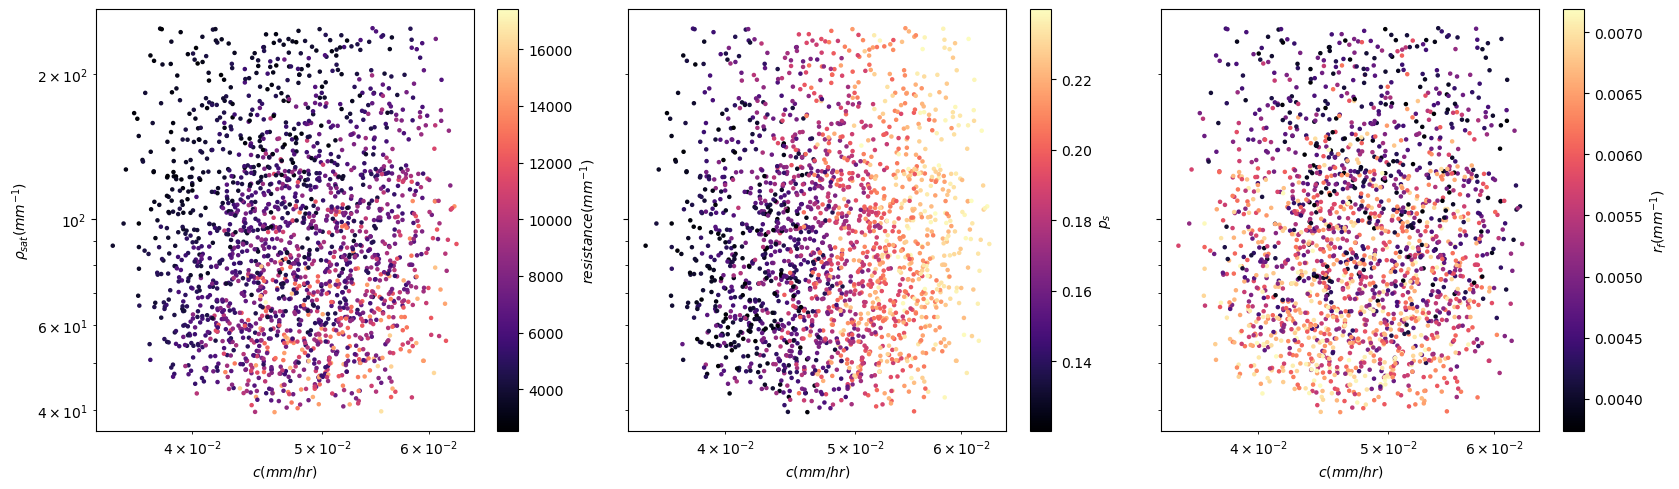

In [38]:
fig, axs = plt.subplots(1,3, sharey = True, figsize = (17, 5))
cm = plt.get_cmap('magma')
sc = axs[0].scatter(in_out_mask[r'$c$'], in_out_mask[r'$\rho _{sat}$'], c = in_out_mask[r'$resistance$'], s = 5, cmap = cm) # , norm=matplotlib.colors.LogNorm())
axs[0].set_xlabel( r'$c(mm/hr)$')
axs[0].set_ylabel(r'$\rho _{sat}(mm^{-1})$')
axs[0].set_xscale('log')
axs[0].set_yscale('log')
cbar = plt.colorbar(sc, ax=axs[0], label = r'$resistance(mm^{-1})$')

sc = axs[1].scatter(in_out_mask[r'$c$'], in_out_mask[r'$\rho _{sat}$'], c = in_out_mask[r'$p_s$'], s = 5, cmap = cm) # , norm=matplotlib.colors.LogNorm())
axs[1].set_xlabel( r'$c(mm/hr)$')
axs[1].set_xscale('log')
axs[1].set_yscale('log')
cbar = plt.colorbar(sc, ax=axs[1], label = r'$p_s$')

sc = axs[2].scatter(in_out_mask[r'$c$'], in_out_mask[r'$\rho _{sat}$'], c = in_out_mask[r'$r_f$'], s = 5, cmap = cm) # , norm=matplotlib.colors.LogNorm())
axs[2].set_xlabel( r'$c(mm/hr)$')
axs[2].set_xscale('log')
axs[2].set_yscale('log')
cbar = plt.colorbar(sc, ax=axs[2], label = r'$r_f(mm^{-1})$')

plt.tight_layout()

# plt.savefig('rho_c.svg')

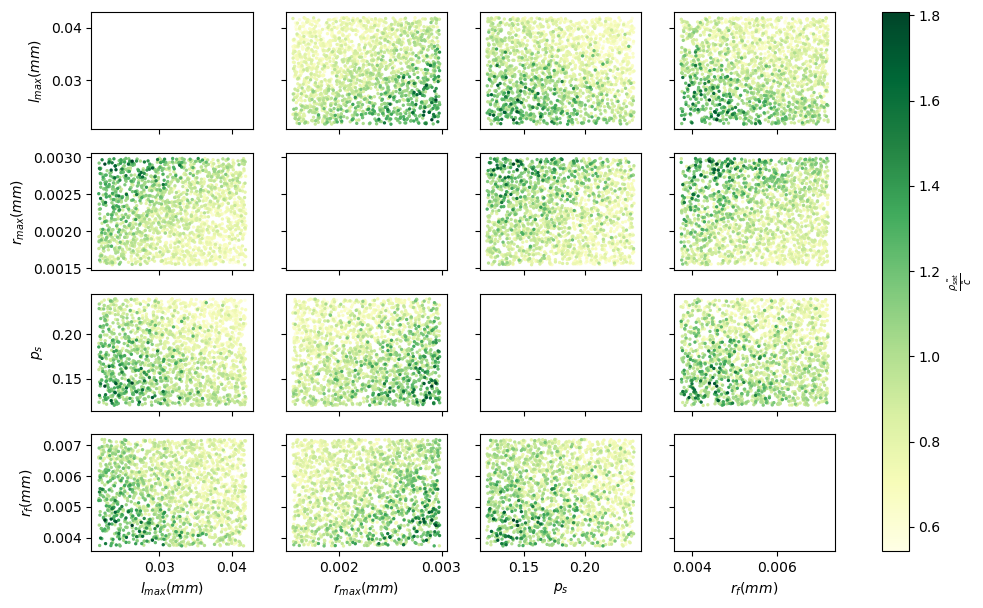

In [39]:

to_plot = [r'$l_{max}$', r'$r_{max}$', r'$p_s$', r'$r_f$']
plot_labels = [r'$l_{max}(mm)$', r'$r_{max}(mm)$', r'$p_s$', r'$r_f(mm)$']
color = r'$\frac{\tilde{\rho_{sat}}}{\tilde{c}}$'
in_out_mask.sort_values(by=[color], ascending=True, inplace = True)
cm = plt.get_cmap('YlGn')
fig2, ax2 = plt.subplots(4, 4, figsize = (12, 7), sharey = 'row',sharex = 'col')
for i in range(4):
    for j in range(4):
        if i != j:
            sc = ax2[i, j].scatter(in_out_mask[to_plot[j]], in_out_mask[to_plot[i]], c = in_out_mask[color], cmap = cm, s= 2)

fig2.colorbar(sc, ax=ax2, label = color)
ax2[0,0].set_ylabel(plot_labels[0])
ax2[1,0].set_ylabel(plot_labels[1])
ax2[2,0].set_ylabel(plot_labels[2])
ax2[3,0].set_ylabel(plot_labels[3])
ax2[3,0].set_xlabel(plot_labels[0])
ax2[3,1].set_xlabel(plot_labels[1])
ax2[3,2].set_xlabel(plot_labels[2])
ax2[3,3].set_xlabel(plot_labels[3])

# plt.savefig('pairwise_ratio.svg')

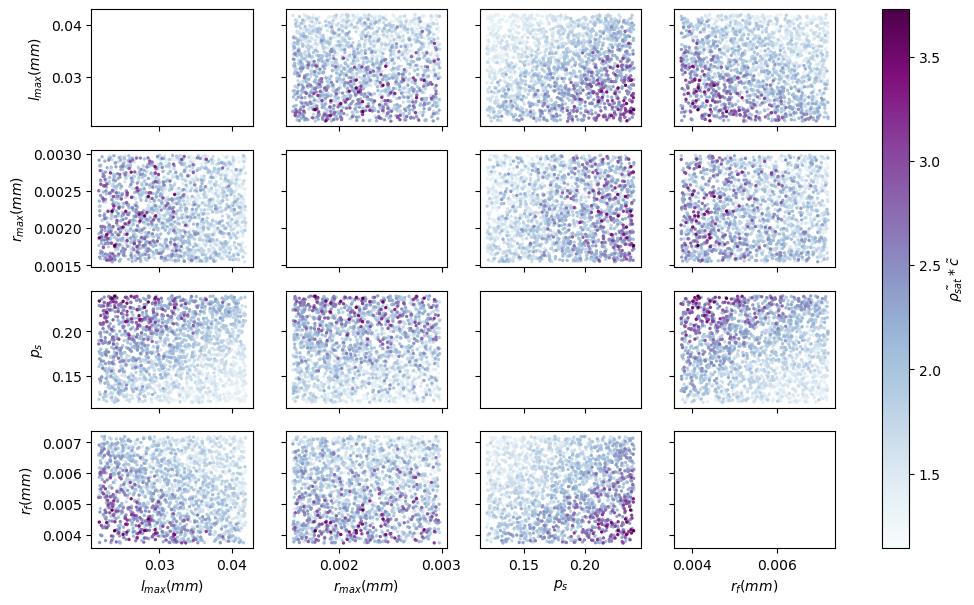

In [40]:
to_plot = [r'$l_{max}$', r'$r_{max}$', r'$p_s$', r'$r_f$']
plot_labels = [r'$l_{max}(mm)$', r'$r_{max}(mm)$', r'$p_s$', r'$r_f(mm)$']
color = r'$\tilde{\rho_{sat}} * \tilde{c}$'
in_out_mask.sort_values(by=[color], ascending=True, inplace = True)
cm = plt.get_cmap('BuPu')
fig2, ax2 = plt.subplots(4, 4, figsize = (12, 7), sharey = 'row',sharex = 'col')
for i in range(4):
    for j in range(4):
        if i != j:
            sc = ax2[i, j].scatter(in_out_mask[to_plot[j]], in_out_mask[to_plot[i]], c = in_out_mask[color], cmap = cm, s = 2)

fig2.colorbar(sc, ax=ax2, label = color)
ax2[0,0].set_ylabel(plot_labels[0])
ax2[1,0].set_ylabel(plot_labels[1])
ax2[2,0].set_ylabel(plot_labels[2])
ax2[3,0].set_ylabel(plot_labels[3])
ax2[3,0].set_xlabel(plot_labels[0])
ax2[3,1].set_xlabel(plot_labels[1])
ax2[3,2].set_xlabel(plot_labels[2])
ax2[3,3].set_xlabel(plot_labels[3])

# plt.savefig('pairwise_product.svg')

In [50]:
# color = 'c'
# markers = ['.', 's', 's']
# fig, ax = plt.subplots()
# cm = plt.get_cmap('RdYlBu')
# for to, d in rc.groupby('tradeoff'):
#     sc = ax.scatter(d[plot1], d[plot2], c = d[color], s = 5, marker = markers[to], cmap = cm)
# ax.set_xlabel(plot1)
# ax.set_ylabel(plot2)
# ax.set_xscale('log')
# ax.set_yscale('log')
# fig.colorbar(sc, ax=ax, label = color)

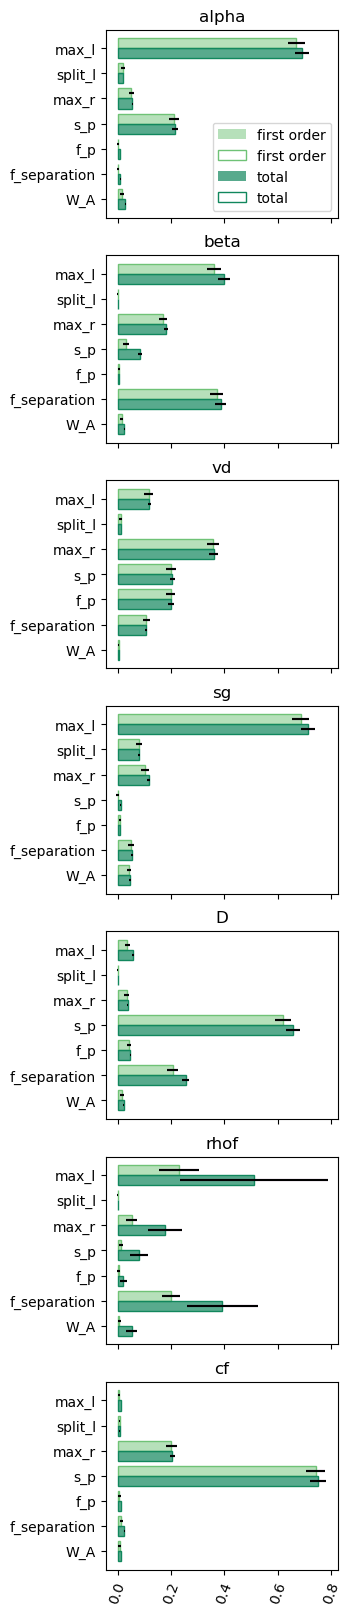

In [61]:
fig, ax = plt.subplots(7, 1, figsize = (3, 20), sharex = True)
PDE_pars = ['alpha', 'beta', 'vd', 'sg', 'D', 'rhof', 'cf']
ABM_inputs = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/2sobol1_' + 'alpha' + '.csv').to_numpy().reshape(-1, 3)[:, 0]
x = np.arange(0, 5 * len(ABM_inputs), 5) 
width = 2
for i in range(7):
    sobol1 = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/2sobol1_' + PDE_pars[i] + '.csv').to_numpy().reshape(-1, 3)
    # sobol1[:, 1][(sobol1[:, 1] - sobol1[:, 2]) < 0] = 0
    # sobol1[:, 2][(sobol1[:, 1] - sobol1[:, 2]) < 0] = 0
    sobolt = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/2sobolt_' + PDE_pars[i] + '.csv').to_numpy().reshape(-1, 3)
    # sobolt[:, 1][(sobolt[:, 1] - sobolt[:, 2]) < 0] = 0
    # sobolt[:, 2][(sobolt[:, 1] - sobolt[:, 2]) < 0] = 0
    ax[i].barh(x - 1, sobol1[:, 1], width, xerr= sobol1[:, 2] / 2, color = 'xkcd:soft green', ecolor = 'purple', label = 'first order', alpha = 0.5)
    ax[i].barh(x - 1, sobol1[:, 1], width, xerr= sobol1[:, 2] / 2, color = 'None', edgecolor = 'xkcd:soft green', label = 'first order')
    ax[i].barh(x + 1, sobolt[:, 1], width, xerr= sobolt[:, 2] / 2, color = 'xkcd:dark sea green', ecolor = 'purple', label = 'total', alpha = 0.7)
    ax[i].barh(x + 1, sobolt[:, 1], width, xerr= sobolt[:, 2] / 2, color = 'None', edgecolor = 'xkcd:dark sea green', label = 'total')
    ax[i].tick_params(axis='x', labelrotation=70)
    ax[i].set_title(PDE_pars[i])
    ax[i].set_yticks(x, ABM_inputs)
    ax[i].invert_yaxis()
ax[0].legend()
plt.savefig('sobol_si.svg')

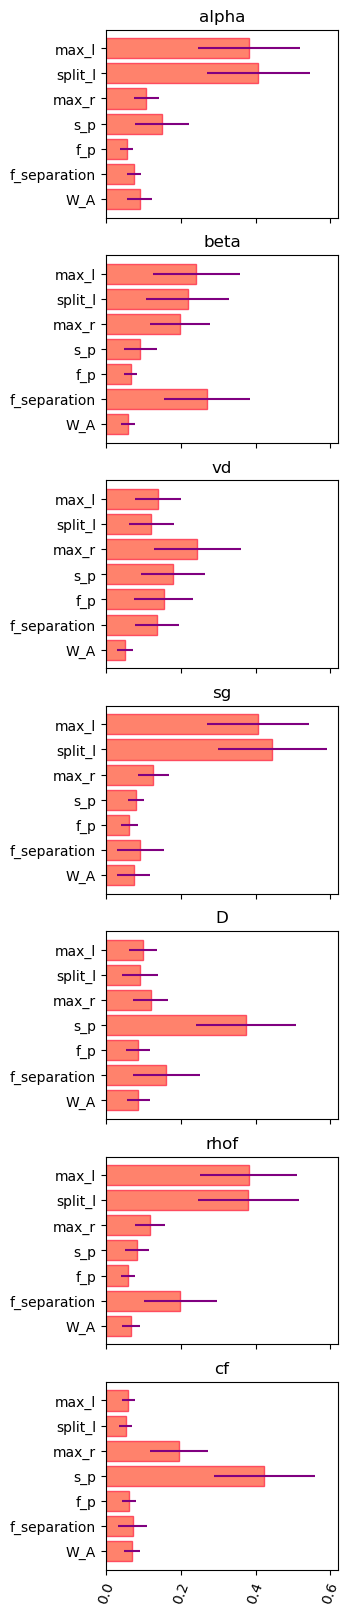

In [59]:
fig, ax = plt.subplots(7, 1, figsize = (3, 20), sharex = True)
for i in range(7):
    pawn = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/2pawn_' + PDE_pars[i] + '.csv').to_numpy().reshape(-1, 7)
    # sobol[:, 1][(sobol[:, 1] - sobol[:, 2]) < 0] = 0
     #sobol[:, 2][(sobol[:, 1] - sobol[:, 2]) < 0] = 0
    ax[i].barh(pawn[:,0], pawn[:, 3], xerr= pawn[:, 6], color = 'tomato', edgecolor = 'xkcd:lightish red', ecolor = 'purple', alpha = 0.8)
    ax[i].tick_params(axis='x', labelrotation=70)
    ax[i].set_title(PDE_pars[i])
    ax[i].invert_yaxis()
# plt.savefig('pawn_si.svg')

In [53]:
# fig, ax = plt.subplots(1, 7, figsize = (60, 8))
# pars = ['alpha', 'beta', 'vd', 'sg', 'D', 'rhof', 'cf']
# for i in range(7):
#     sobol = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/sobol2_' + pars[i] + '.csv').to_numpy().reshape(-1, 3)
#     # sobol[:, 1][(sobol[:, 1] - sobol[:, 2]) < 0] = 0plt his
#     # sobol[:, 2][(sobol[:, 1] - sobol[:, 2]) < 0] = 0
#     ax[i].bar(sobol[:, 0], sobol[:, 1], yerr= sobol[:, 2], color = 'y', ecolor = 'purple')
#     ax[i].tick_params(axis='x', labelrotation=70)
#     ax[i].set_title(pars[i])
# fig.suptitle('Sobol Second Order Sensitivity Indices')

In [54]:
# fig, ax = plt.subplots(1, 7, figsize = (30, 4), sharey = 'row')
# pars = ['alpha', 'beta', 'vd', 'sg', 'D', 'rhof', 'cf']
# for i in range(7):
#     pawn = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SAlib_output/pawn_' + pars[i] + '.csv').to_numpy().reshape(-1, 7)
#     pawn[:, 3][(pawn[:, 3] - pawn[:, 6]) < 0] = 0
#     pawn[:, 6][(pawn[:, 3] - pawn[:, 6]) < 0] = 0
#     ax[i].bar(pawn[:,0], pawn[:, 3], yerr= pawn[:, 6], color = 'tab:orange', ecolor = 'purple')
#     ax[i].tick_params(axis='x', labelrotation=70)
#     ax[i].set_title(pars[i])
# fig.suptitle('PAWN Sensitivity Indices')

In [55]:
# fig, ax = plt.subplots(1, 7, figsize = (30, 4))
# pars = ['alpha', 'beta', 'vd', 'sg', 'D', 'rhof', 'cf']
# for i in range(7):
#     sobol = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/sobol1_' + pars[i] + '.csv').to_numpy().reshape(-1, 3)
#     # sobol[:, 1][(sobol[:, 1] - sobol[:, 2]) < 0] = 0
#     # sobol[:, 2][(sobol[:, 1] - sobol[:, 2]) < 0] = 0
#     ax[i].bar(sobol[:,0], sobol[:, 1], yerr= sobol[:, 2], color = 'y', ecolor = 'purple')
#     ax[i].tick_params(axis='x', labelrotation=70)
#     ax[i].set_title(pars[i])
# fig.suptitle('Sobol First Order Sensitivity Indices')

In [56]:
# ABM_inputs = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobol1_' + 'alpha' + '.csv').to_numpy().reshape(-1, 3)[:, 0]
# PDE_par = [r'$\alpha$', r'$\beta$', r'$v_d$', r'$s_g$', r'$D$', r'$\rho_{sat}$', r'$c$']

# PDE_sobol1 = [pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobol1_alpha.csv').to_numpy().reshape(-1, 3)[:, 1].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobol1_beta.csv').to_numpy().reshape(-1, 3)[:, 1].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobol1_vd.csv').to_numpy().reshape(-1, 3)[:, 1].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobol1_sg.csv').to_numpy().reshape(-1, 3)[:, 1].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobol1_D.csv').to_numpy().reshape(-1, 3)[:, 1].astype(np.float64),
#              pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobol1_rhof.csv').to_numpy().reshape(-1, 3)[:, 1].astype(np.float64),
#              pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobol1_cf.csv').to_numpy().reshape(-1, 3)[:, 1].astype(np.float64)]

# PDE_sobol1_err = [pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobol1_alpha.csv').to_numpy().reshape(-1, 3)[:, 2].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobol1_beta.csv').to_numpy().reshape(-1, 3)[:, 2].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobol1_vd.csv').to_numpy().reshape(-1, 3)[:, 2].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobol1_sg.csv').to_numpy().reshape(-1, 3)[:, 2].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobol1_D.csv').to_numpy().reshape(-1, 3)[:, 2].astype(np.float64),
#              pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobol1_rhof.csv').to_numpy().reshape(-1, 3)[:, 2].astype(np.float64),
#              pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobol1_cf.csv').to_numpy().reshape(-1, 3)[:, 2].astype(np.float64)]

# PDE_sobolt = [pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobolt_alpha.csv').to_numpy().reshape(-1, 3)[:, 1].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobolt_beta.csv').to_numpy().reshape(-1, 3)[:, 1].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobolt_vd.csv').to_numpy().reshape(-1, 3)[:, 1].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobolt_sg.csv').to_numpy().reshape(-1, 3)[:, 1].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobolt_D.csv').to_numpy().reshape(-1, 3)[:, 1].astype(np.float64),
#              pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobolt_rhof.csv').to_numpy().reshape(-1, 3)[:, 1].astype(np.float64),
#              pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobolt_cf.csv').to_numpy().reshape(-1, 3)[:, 1].astype(np.float64)]

# PDE_sobolt_err = [pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobolt_alpha.csv').to_numpy().reshape(-1, 3)[:, 2].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobolt_beta.csv').to_numpy().reshape(-1, 3)[:, 2].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobolt_vd.csv').to_numpy().reshape(-1, 3)[:, 2].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobolt_sg.csv').to_numpy().reshape(-1, 3)[:, 2].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobolt_D.csv').to_numpy().reshape(-1, 3)[:, 2].astype(np.float64),
#              pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobolt_rhof.csv').to_numpy().reshape(-1, 3)[:, 2].astype(np.float64),
#              pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/sobolt_cf.csv').to_numpy().reshape(-1, 3)[:, 2].astype(np.float64)]

# PDE_pawn = [pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/pawn_alpha.csv').to_numpy().reshape(-1, 7)[:, 3].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/pawn_beta.csv').to_numpy().reshape(-1, 7)[:, 3].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/pawn_vd.csv').to_numpy().reshape(-1, 7)[:, 3].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/pawn_sg.csv').to_numpy().reshape(-1, 7)[:, 3].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/pawn_D.csv').to_numpy().reshape(-1, 7)[:, 3].astype(np.float64),
#              pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/pawn_rhof.csv').to_numpy().reshape(-1, 7)[:, 3].astype(np.float64),
#              pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/pawn_cf.csv').to_numpy().reshape(-1, 7)[:, 3].astype(np.float64)]

# PDE_pawn_err = [pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/pawn_alpha.csv').to_numpy().reshape(-1, 7)[:, 6].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/pawn_beta.csv').to_numpy().reshape(-1, 7)[:, 6].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/pawn_vd.csv').to_numpy().reshape(-1, 7)[:, 6].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/pawn_sg.csv').to_numpy().reshape(-1, 7)[:, 6].astype(np.float64),
#           pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/pawn_D.csv').to_numpy().reshape(-1, 7)[:, 6].astype(np.float64),
#              pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/pawn_rhof.csv').to_numpy().reshape(-1, 7)[:, 6].astype(np.float64),
#              pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/SALib_output/pawn_cf.csv').to_numpy().reshape(-1, 7)[:, 6].astype(np.float64)]

# colors = ['purple', 'tomato', 'y', 'tab:orange', 'steelblue', 'xkcd:yellowish', 'slateblue']
# x = np.arange(len(ABM_inputs)) * 2  # the label locations
# width = 0.20  # the width of the bars

# fig, axs = plt.subplots(1, 3, figsize = (15, 12))

# multiplier = 0
# for par, si, si_err, color in zip(PDE_par, PDE_sobol1, PDE_sobol1_err, colors):
#     offset = width * multiplier
#     rects = axs[0].barh(x + offset, si, width, xerr = si_err, label=par, color = color)
#     # ax.bar_label(rects, padding=5)
#     multiplier += 1

# # Add some text for labels, title and custom x-axis tick labels, etc.
# axs[0].set_xlabel('sensitivity')
# axs[0].set_yticks(x + width, ABM_inputs)
# axs[0].tick_params(axis='y', labelrotation=30)
# axs[0].invert_yaxis()
# axs[0].set_title('Sobol first order indices')

# multiplier = 0
# for par, si, si_err, color in zip(PDE_par, PDE_sobolt, PDE_sobolt_err, colors):
#     offset = width * multiplier
#     rects = axs[1].barh(x + offset, si, width, xerr = si_err, label=par, color = color)
#     # ax.bar_label(rects, padding=5)
#     multiplier += 1

# axs[1].set_xlabel('sensitivity')
# axs[1].set_yticks(x + width, '')
# axs[1].tick_params(axis='y', labelrotation=30)
# axs[1].invert_yaxis()
# axs[1].set_title('Sobol total sensitivity')

# multiplier = 0
# for par, si, si_err, color in zip(PDE_par, PDE_pawn, PDE_pawn_err, colors):
#     offset = width * multiplier
#     rects = axs[2].barh(x + offset, si, width, xerr = si_err, label=par, color = color)
#     # ax.bar_label(rects, padding=5)
#     multiplier += 1

# axs[2].set_xlabel('sensitivity')
# axs[2].set_yticks(x + width, '')
# axs[2].legend(loc='lower right', ncols=3)
# axs[2].tick_params(axis='y', labelrotation=30)
# axs[2].invert_yaxis()
# axs[2].set_title('PAWN sensitivity')

# fig.tight_layout()

In [26]:
in_out_mask

,$l_{max}$,$l_{split}$,$r_{max}$,$p_s$,$p_f$,$r_f$,$W_A$,$resistance$,$\alpha$,$\beta$,...,$s_g$,$D$,$\rho _{sat}$,$c$,$\bar{\rho_{sat}}$,$\bar{c}$,$\tilde{\rho_{sat}}$,$\tilde{c}$,$\tilde{\rho_{sat}} * \tilde{c}$,$\frac{\tilde{\rho_{sat}}}{\tilde{c}}$
0,0.041546,0.037816,0.001697,0.174475,0.007377,0.005062,0.000068,14434.800232,0.304960,0.017271,...,0.076161,0.000453,50.098184,0.050748,30.482130,0.035464,1.050072,1.565180,1.643552,0.670895
1,0.029721,0.025769,0.002931,0.178146,0.008555,0.006791,0.000064,3459.230648,0.326459,0.010150,...,0.078459,0.000247,77.071355,0.041067,52.211812,0.028518,1.178565,1.220335,1.438243,0.965772
2,0.037842,0.032452,0.002063,0.129309,0.009257,0.004742,0.000116,8890.653155,0.248703,0.008968,...,0.087487,0.000273,67.666227,0.042383,43.761744,0.026739,1.133761,1.267212,1.436716,0.894689
3,0.031789,0.028280,0.002262,0.199519,0.006982,0.003833,0.000079,6211.041612,0.348884,0.005988,...,0.090874,0.000621,155.441789,0.053028,110.473163,0.040657,1.551901,1.646412,2.555069,0.942595
4,0.040978,0.035057,0.002458,0.176016,0.006622,0.003887,0.000063,6785.099683,0.316698,0.010370,...,0.085651,0.000468,76.748701,0.047560,53.714327,0.034699,1.177028,1.451641,1.708622,0.810825
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,0.035463,0.032315,0.001570,0.125148,0.007472,0.004842,0.000078,14388.002378,0.276837,0.010822,...,0.082384,0.000346,69.079142,0.044972,41.276944,0.030191,1.140492,1.359453,1.550446,0.838934
1996,0.037880,0.033243,0.002625,0.205028,0.011926,0.005510,0.000098,5495.435755,0.285521,0.011551,...,0.081867,0.000364,60.842975,0.049720,42.865587,0.032711,1.101257,1.528596,1.683377,0.720437
1997,0.038449,0.033945,0.002282,0.209169,0.010888,0.006330,0.000119,7385.403639,0.293522,0.016273,...,0.082215,0.000344,52.270984,0.051201,32.839698,0.034998,1.060422,1.581317,1.676864,0.670594
1998,0.033741,0.029135,0.002074,0.145782,0.010489,0.005683,0.000076,7847.741195,0.296155,0.011543,...,0.085911,0.000297,61.453198,0.045820,41.575418,0.030836,1.104164,1.389657,1.534409,0.794559


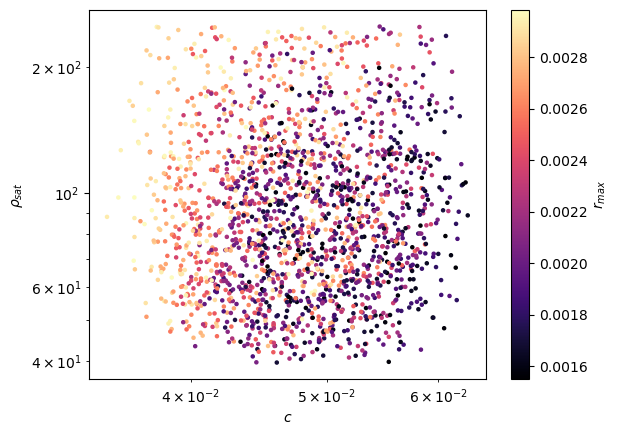

In [46]:
plot1 = r'$c$'
plot2 = r'$\rho _{sat}$'
plot3 = r'$r_{max}$'
fig, axs = plt.subplots()
cm = plt.get_cmap('magma')
sc = axs.scatter(in_out_mask[plot1], in_out_mask[plot2], c = in_out_mask[plot3], s = 5, cmap = cm) # , norm=matplotlib.colors.LogNorm())
axs.set_xlabel( plot1)
axs.set_ylabel(plot2)
axs.set_xscale('log')
axs.set_yscale('log')
cbar = plt.colorbar(sc, ax=axs, label = plot3)

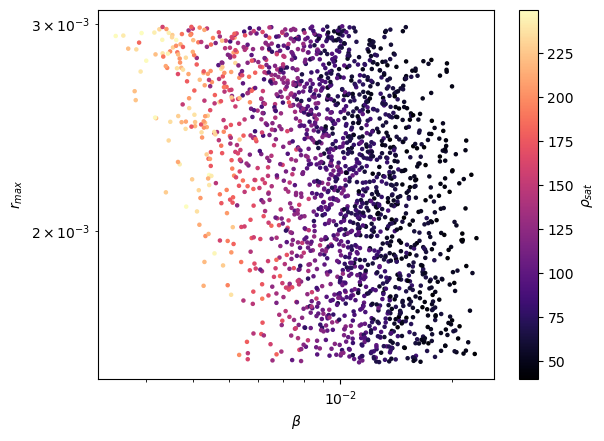

In [45]:
plot1 = r'$\beta$'
plot2 = r'$r_{max}$'
plot3 = r'$\rho _{sat}$'
fig, axs = plt.subplots()
cm = plt.get_cmap('magma')
sc = axs.scatter(in_out_mask[plot1], in_out_mask[plot2], c = in_out_mask[plot3], s = 5, cmap = cm) # , norm=matplotlib.colors.LogNorm())
axs.set_xlabel( plot1)
axs.set_ylabel(plot2)
axs.set_xscale('log')
axs.set_yscale('log')
cbar = plt.colorbar(sc, ax=axs, label = plot3)
# fig.savefig('r_beta_sg.svg')

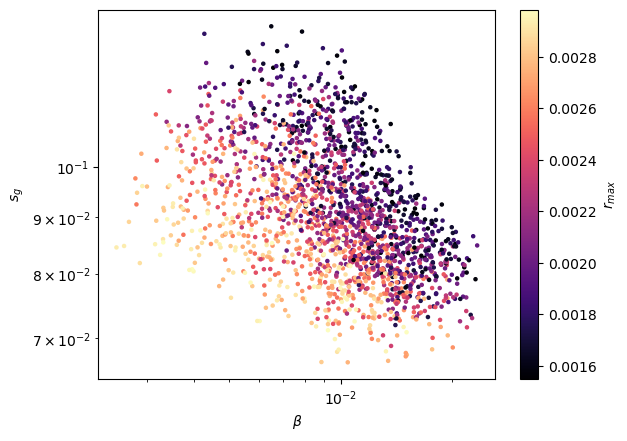

In [44]:
plot1 = r'$\beta$'
plot2 = r'$s_g$'
plot3 = r'$r_{max}$'
fig, axs = plt.subplots()
cm = plt.get_cmap('magma')
sc = axs.scatter(in_out_mask[plot1], in_out_mask[plot2], c = in_out_mask[plot3], s = 5, cmap = cm) # , norm=matplotlib.colors.LogNorm())
axs.set_xlabel( plot1)
axs.set_ylabel(plot2)
axs.set_xscale('log')
axs.set_yscale('log')
cbar = plt.colorbar(sc, ax=axs, label = plot3)